# **Agentic AI for ZIF-8 Nanocrystal Synthesis: Scientific Retrieval, MCP Tool Integration and Experimental-Data Modelling**

## **1. Scientific Problem Definition**

### **Context**

Zeolitic imidazolate framework-8 (ZIF-8) is a microporous metal–organic framework formed from Zn(II) centres and 2-methylimidazolate linkers. Its synthesis involves nucleation, crystal growth and crystallisation processes influenced by precursor chemistry, reagent ratios, solvent composition, temperature, reaction time and other experimental conditions.

Published ZIF-8 synthesis information is distributed across journal articles, theses, supplementary materials and research datasets. Differences in experimental procedures, reporting completeness and characterisation methods can complicate comparisons between reported particle sizes and synthesis conditions.

This project focuses on **freely formed ZIF-8 nanocrystals synthesised in solution**, rather than crystals grown directly on membranes or other supports. Supported-growth studies may provide relevant background, but their reported crystal characteristics are not automatically comparable with those of free particles.

Large language models (LLMs) can coordinate scientific information retrieval and computational tools, while conventional machine-learning methods can investigate quantitative relationships in structured experimental datasets. Together, agentic AI and experimental-data modelling provide a framework for connecting scientific information retrieval, computational analysis and source-traceable interpretation of results.

The project therefore develops a **research prototype** combining Claude-based agentic tool use, external scientific databases, a genuine Model Context Protocol (MCP) server, structured experimental provenance and preliminary particle-size regression.

### **Objective and Scope**

The objective is to **implement and evaluate a working scientific AI-agent prototype** for retrieving ZIF-8 literature, accessing traceable experimental information and invoking a preliminary experimental-data model through MCP.

The project is organised around six objectives:

**1. Scientific literature retrieval:** Integrate OpenAlex and Crossref to retrieve publications and bibliographic metadata relevant to ZIF-8 synthesis.

**2. Structured evidence management:** Store literature metadata and manually verified experimental information in SQLite, preserving source references and explicitly identifying missing values.

**3. Agentic scientific tool use:** Implement a Claude research agent capable of selecting and executing external scientific tools through a real MCP server.

**4. Experimental dataset assessment:** Retrieve and inspect a published ZIF-8 dataset, examine recorded synthesis variables, identify repeated input combinations and assess their implications for data preparation and model evaluation.

**5. Regression modelling and validation:** Compare conventional regression methods for predicting experimentally measured ZIF-8 particle size, using grouped cross-validation to prevent identical recorded input combinations from appearing in both training and validation folds.

**6. Agent-accessible prediction with safeguards:** Expose the experimental regression model as an MCP tool, distinguish recorded and untested input combinations, reject inputs outside observed feature ranges and communicate source provenance, model status and validation information.

A separate **synthetic-data regression demonstration** is retained to test the computational architecture. Its predictions and performance metrics are not treated as experimental evidence.

### **Research Questions**

The notebook investigates the following questions:

**1.** Can a Claude-based agent retrieve relevant ZIF-8 literature and access structured experimental records using external scientific tools?

**2.** Can a genuine MCP server provide a common interface for scientific literature retrieval, experimental-record access and machine-learning prediction?

**3.** Can source provenance, missing information and differences in experimental scope be recorded explicitly rather than inferred or silently filled in?

**4.** What data-quality and comparability concerns arise when a published ZIF-8 experimental dataset is prepared for particle-size regression?

**5.** Do Random Forest and Ridge regression improve prediction of measured particle size relative to a training-mean baseline under grouped cross-validation?

**6.** Can an experimental prediction tool distinguish recorded conditions, untested combinations within the observed feature ranges and inputs outside those ranges?

**7.** Can Claude autonomously select the experimental MCP prediction tool and communicate its result without presenting a fitted-model estimate as a new experimental measurement?

**8.** How can model provenance, validation information and experimental-domain checks be incorporated into an agentic scientific workflow to support transparent interpretation of predictions?

These questions are evaluated through the retrieval results, database records, model comparisons, MCP execution tests and selected Claude-agent demonstrations presented in the notebook.

### **Problem Formulation**

The prototype addresses a **scientific information-retrieval, tool-orchestration and preliminary regression problem.**

Given a ZIF-8 research question, Claude can select from tools exposed through MCP. These tools provide access to scientific literature searches, a database of verified experimental records and particle-size prediction functions.

Two distinct sources of experimental evidence are used:

- **Literature-derived experimental records:** A manually verified synthesis record is stored in SQLite with its supporting source and available experimental parameters. Missing values are retained as missing rather than estimated.

- **Published experimental modelling dataset:** A separate Zenodo dataset containing 27 ZIF-8 particle-size records is retrieved and analysed. Its recorded synthesis factors are used to train and evaluate preliminary regression models.

The experimental regression task is formulated as:

**Inputs:** Reported Hmim quantity, synthesis temperature and solvent polarity, using the numerical scales provided by the source dataset.

**Target:** Mean ZIF-8 particle size measured using TEM/ImageJ, reported in nanometres.

**Validation:** Five-fold grouped cross-validation, grouping records with identical values of the three selected model inputs.

**Model selection:** Comparison of a training-mean baseline, Ridge regression and Random Forest regression.

**Agent integration:** The selected experimental model is made available through MCP. The prediction tool checks observed feature ranges and whether the complete input combination is represented in the modelling dataset.

An input combination appearing in the dataset does not mean that the model's returned value is an experimental measurement. All outputs from the regression tool remain **model-derived estimates.**

### **Data Sources and Scientific Provenance**

**Scientific literature and metadata**

OpenAlex and Crossref are used for programmatic publication retrieval. Selected literature sources are curated and stored with bibliographic identifiers and source references.

**Verified experimental literature record**

A source-traceable record of solution-grown ZIF-8 nanocrystals is extracted from a doctoral thesis and stored in SQLite. Reported synthesis details and particle-characterisation methods are distinguished from information that is unavailable or not numerically specified.

**Published experimental dataset**

The experimental modelling data originate from:

Du, Y. (2024). Characterization results and synthesis parameters of ZIF-8. Zenodo. https://doi.org/10.5281/zenodo.14063747

The spreadsheet contains **27 particle-size records and 23 distinct combinations of recorded model inputs.** Some repeated input combinations have different reported particle sizes. The notebook retains these observations and uses grouped validation rather than treating repeated conditions as independent train/test combinations.

The selected model features are Hmim quantity, temperature and polarity. Other recorded solvent-property columns are inspected but not included as additional model inputs. Physical units or definitions that are not established from the source spreadsheet are not invented.

**Synthetic demonstration data**

A separately generated synthetic dataset is used to demonstrate model training, persistence and MCP-based invocation before introducing the published experimental model. Synthetic results are labelled as illustrative and are not used to support experimental synthesis conclusions.

### **Research Approach and Notebook Organisation**

The project combines scientific literature retrieval, structured evidence management, agentic tool orchestration and experimental-data regression within a single computational workflow.

The notebook follows a progressive research approach:

**1. Scientific information retrieval and evidence management:** Retrieve ZIF-8 publications through scientific databases, curate relevant sources and store traceable experimental information in SQLite.

**2. Claude-based agent development:** Implement an agent capable of selecting and invoking scientific tools, including tools made available through the Model Context Protocol (MCP).

**3. Computational demonstration:** Develop a synthetic-data regression example to establish the model-training and tool-invocation workflow independently of experimental evidence.

**4. Experimental dataset preparation:** Retrieve a published ZIF-8 dataset, inspect its structure and recorded synthesis conditions, and prepare the measured particle-size data for modelling.

**5. Experimental regression and validation:** Compare regression approaches using grouped cross-validation and examine their prediction errors.

**6. Scientific tool integration:** Expose the experimental model through MCP, incorporating source provenance, recorded-condition checks and observed-domain safeguards.

**7. Agentic workflow demonstration:** Evaluate Claude's ability to invoke the experimental prediction tool and communicate its output in a scientifically interpretable form.

This structure connects scientific data acquisition and experimental analysis with an executable AI-agent architecture. Quantitative results, scientific interpretation, conclusions and recommendations for further development are presented in the relevant subsequent sections.


## **2. Environment Setup**

In [51]:
# Install required Python libraries

%pip install -q requests anthropic pandas

In [52]:
# Import core libraries and configure the scientific research environment

import os
import sys
import json
import time
import sqlite3
import requests
import re
import io
import ast
import asyncio
import subprocess

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

from anthropic import Anthropic

DB_PATH = Path("zif8_literature.sqlite")
OPENALEX_URL = "https://api.openalex.org/works"
MODEL = "claude-haiku-4-5-20251001"

print("Anthropic API key configured:", bool(os.getenv("ANTHROPIC_API_KEY")))

Anthropic API key configured: True


## **3. Scientific Data Infrastructure**
This section establishes the literature retrieval and storage infrastructure using OpenAlex and SQLite. Retrieved publications are organised with bibliographic metadata and source identifiers to support traceable scientific research.

### **3.1 Scientific Literature Tool: OpenAlex**

In [53]:
# Retrieve scientific publications and bibliographic metadata using the OpenAlex API

def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return None
    positions = [(pos, word) for word, indices in inverted_index.items() for pos in indices]
    return ' '.join(word for _, word in sorted(positions))


def search_openalex(query: str, limit: int = 5) -> dict:
    """Search real scientific literature. Returns compact, source-linked records."""
    limit = max(1, min(int(limit), 10))
    params = {'search': query, 'per-page': limit, 'select':
              'id,doi,title,publication_year,authorships,abstract_inverted_index,primary_location'}
    response = requests.get(OPENALEX_URL, params=params, timeout=25,
                            headers={'User-Agent': 'ZIF8ResearchAgent/0.1 (academic demonstration)'})
    response.raise_for_status()
    papers = []
    for work in response.json().get('results', []):
        loc = work.get('primary_location') or {}
        papers.append({
            'openalex_id': work['id'], 'doi': work.get('doi'),
            'title': work.get('title'), 'year': work.get('publication_year'),
            'authors': ', '.join(a.get('author', {}).get('display_name', '')
                                 for a in work.get('authorships', [])[:5]),
            'abstract': reconstruct_abstract(work.get('abstract_inverted_index')),
            'landing_page': loc.get('landing_page_url'),
            'pdf_url': (loc.get('pdf_url') if loc else None),
            'retrieved_at': datetime.now(timezone.utc).isoformat()
        })
    return {'query': query, 'count': len(papers), 'papers': papers}

In [54]:
# Test scientific literature retrieval and inspect publication metadata

search_results = search_openalex(
    query="ZIF-8 nanocrystal synthesis particle size morphology",
    limit=5
)

papers_df = pd.DataFrame(search_results["papers"])

print(f"Publications retrieved: {search_results['count']}")

display(
    papers_df[
        ["title", "year", "doi", "landing_page"]
    ]
)

Publications retrieved: 5


,title,year,doi,landing_page
0,Influence of the solvent in the synthesis of z...,2014,https://doi.org/10.1016/j.jcis.2014.03.014,https://doi.org/10.1016/j.jcis.2014.03.014
1,Synthesis and characterization of ZIF-8 nanopa...,2017,https://doi.org/10.1016/j.jddst.2017.07.004,https://doi.org/10.1016/j.jddst.2017.07.004
2,Sized-Controlled ZIF-8 Nanoparticle Synthesis ...,2020,https://doi.org/10.1021/acssuschemeng.9b07593,https://doi.org/10.1021/acssuschemeng.9b07593
3,Synthesis of ZIF-8 Nanocrystals Mediated by CO...,2020,https://doi.org/10.1021/acs.langmuir.0c02549,https://doi.org/10.1021/acs.langmuir.0c02549
4,Colloidal metal–organic framework particles: t...,2019,https://doi.org/10.1039/c9cs00472f,https://doi.org/10.1039/c9cs00472f


### **3.2 SQLite: Structured Storage and Provenance**

In [55]:
# Initialise SQLite storage for scientific publication metadata and provenance

def init_db(path=DB_PATH):
    with sqlite3.connect(path) as conn:
        conn.execute('''CREATE TABLE IF NOT EXISTS papers (
            openalex_id TEXT PRIMARY KEY, doi TEXT, title TEXT, year INTEGER,
            authors TEXT, abstract TEXT, landing_page TEXT, pdf_url TEXT,
            retrieved_at TEXT)''')


def save_papers(papers, path=DB_PATH):
    fields = ['openalex_id','doi','title','year','authors','abstract',
              'landing_page','pdf_url','retrieved_at']
    with sqlite3.connect(path) as conn:
        conn.executemany(
            f"INSERT OR REPLACE INTO papers ({','.join(fields)}) VALUES ({','.join('?' for _ in fields)})",
            [tuple(p.get(field) for field in fields) for p in papers]
        )
    return len(papers)


def list_papers(limit=20, path=DB_PATH):
    with sqlite3.connect(path) as conn:
        return pd.read_sql_query('SELECT title, year, doi, openalex_id FROM papers LIMIT ?',
                                 conn, params=(int(limit),))

init_db()

In [56]:
# Store retrieved publications and verify database records

saved_count = save_papers(search_results["papers"])

print(f"Publication records processed: {saved_count}")

stored_papers_df = list_papers(limit=10)

print(f"Publication records displayed: {len(stored_papers_df)}")

display(stored_papers_df)

Publication records processed: 5
Publication records displayed: 10


,title,year,doi,openalex_id
0,Synthesis and characterization of ZIF-8 and ZI...,2015,https://doi.org/10.17638/02006519,https://openalex.org/W2625969233
1,Continuous microreactor synthesis of ZIF-8 wit...,2015,https://doi.org/10.1016/j.cej.2015.08.071,https://openalex.org/W1462661479
2,Synthesis of ZIF-8 in a deep eutectic solvent ...,2014,https://doi.org/10.1016/j.micromeso.2014.04.016,https://openalex.org/W2087846994
3,Unified roadmap for ZIF-8 Nucleation and Growt...,2023,https://doi.org/10.26434/chemrxiv-2023-6181f,https://openalex.org/W4384826008
4,Dataset of reported synthetic conditions for Z...,2023,https://doi.org/10.5281/zenodo.8153450,https://openalex.org/W4393667677
5,"Development of a new method for synthesis, con...",2024,https://doi.org/10.1016/j.jallcom.2024.174103,https://openalex.org/W4392553531
6,ZIF-8@SiO2 composite nanofiber membrane with b...,2019,https://doi.org/10.1016/j.memsci.2019.03.075,https://openalex.org/W2931319586
7,Preparation of Magnetic CuFe2O4@Ag@ZIF-8 Nanoc...,2019,https://doi.org/10.3390/molecules25010124,https://openalex.org/W2998511042
8,Hydrothermal Synthesis of Zeolitic Imidazolate...,2012,https://doi.org/10.25781/kaust-461g0,https://openalex.org/W180194186
9,"Surfactant‐Free, Size‐Controllable, and Scalab...",2024,https://doi.org/10.1002/smtd.202400236,https://openalex.org/W4396621792


## **4. Claude Agent Architecture and Native Tool Use**
This section implements a Claude-based research agent using Anthropic's native tool-calling interface. The agent can select literature search and database tools, execute them iteratively, and retain a record of tool use.

In [57]:
# Load the Anthropic API key from Google Colab Secrets

from google.colab import userdata

os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY").strip()

print("Anthropic key configured:", bool(os.getenv("ANTHROPIC_API_KEY")))

Anthropic key configured: True


In [58]:
# Verify Claude API connectivity with a minimal scientific query

client = Anthropic()

response = client.messages.create(
    model="claude-haiku-4-5-20251001",
    max_tokens=100,
    messages=[
        {
            "role": "user",
            "content": "In one sentence, explain nucleation during ZIF-8 crystallisation."
        }
    ]
)

print(response.content[0].text)

# ZIF-8 Nucleation

Nucleation during ZIF-8 crystallization is the initial formation of microscopic crystalline clusters of zinc-imidazolate framework through the assembly of Zn²⁺ ions and imidazolate ligands, which must overcome an energy barrier before growing into larger crystals.


In [59]:
# Configure the Claude agent and implement iterative scientific tool selection and execution

TOOLS = [
    {
        "name": "search_scientific_literature",
        "description": (
            "Search OpenAlex for indexed scientific publications. "
            "Save retrieved metadata to SQLite and return titles, DOIs, "
            "publication years, and available abstracts. "
            "Use when additional literature evidence is needed."
        ),
        "input_schema": {
            "type": "object",
            "properties": {
                "query": {
                    "type": "string",
                    "description": "Specific scientific literature search query",
                },
                "limit": {
                    "type": "integer",
                    "minimum": 1,
                    "maximum": 10,
                },
            },
            "required": ["query"],
        },
    },
    {
        "name": "list_stored_papers",
        "description": (
            "Retrieve previously saved scientific publication records "
            "from the local SQLite database."
        ),
        "input_schema": {
            "type": "object",
            "properties": {},
            "required": [],
        },
    },
]

SYSTEM_PROMPT = """You are a scientific literature research agent assisting a chemist.

Focus on solution-based synthesis of freely formed ZIF-8 nanocrystals,
including nucleation, crystal growth, particle size, and morphology.

Use scientific tools to gather evidence before answering.
Search multiple times when necessary.

Never invent DOIs, numerical experimental conditions, solubility,
crystallinity, particle sizes, or measurement results.

Bibliographic metadata and abstracts do not establish complete
experimental procedures.

Cite retrieved publications using DOIs or OpenAlex identifiers.
Distinguish retrieved evidence from scientific hypotheses.
State when full text or supporting information is required.
Do not claim experimental validation or that synthesis was performed.
"""


def execute_tool(name, arguments):
    if name == "search_scientific_literature":
        result = search_openalex(
            arguments["query"],
            arguments.get("limit", 5),
        )
        save_papers(result["papers"])
        return result

    if name == "list_stored_papers":
        return {
            "papers": list_papers().to_dict(orient="records")
        }

    return {"error": f"Unknown tool: {name}"}


def run_agent(question, max_rounds=5):
    if not os.getenv("ANTHROPIC_API_KEY"):
        raise RuntimeError(
            "Set ANTHROPIC_API_KEY in your environment first."
        )

    client = Anthropic()

    messages = [
        {"role": "user", "content": question}
    ]

    audit_log = []

    for round_number in range(max_rounds):
        response = client.messages.create(
            model=MODEL,
            max_tokens=1400,
            system=SYSTEM_PROMPT,
            tools=TOOLS,
            messages=messages,
        )

        messages.append({
            "role": "assistant",
            "content": response.content,
        })

        calls = [
            block
            for block in response.content
            if block.type == "tool_use"
        ]

        if not calls:
            answer = "\n".join(
                block.text
                for block in response.content
                if block.type == "text"
            )

            return {
                "answer": answer,
                "audit_log": audit_log,
            }

        tool_results = []

        for call in calls:
            try:
                result = execute_tool(
                    call.name,
                    call.input,
                )
            except Exception as exc:
                result = {
                    "error": f"{type(exc).__name__}: {exc}"
                }

            audit_log.append({
                "round": round_number + 1,
                "tool": call.name,
                "input": call.input,
                "result_count": result.get("count"),
            })

            tool_results.append({
                "type": "tool_result",
                "tool_use_id": call.id,
                "content": json.dumps(
                    result,
                    ensure_ascii=False,
                    default=str,
                )[:24000],
            })

        messages.append({
            "role": "user",
            "content": tool_results,
        })

    return {
        "answer": (
            "Stopped at the configured tool-use round limit."
        ),
        "audit_log": audit_log,
    }


print("Claude research agent configured.")
print("Native scientific tools:", [tool["name"] for tool in TOOLS])


Claude research agent configured.
Native scientific tools: ['search_scientific_literature', 'list_stored_papers']


## **5. Agent Execution and Scientific Validation**
This section runs the Claude research agent on a ZIF-8 synthesis question and examines its literature retrieval, database persistence and tool-use audit. The results provide an initial test of the native agent workflow before the MCP integration introduced later.

In [60]:
# Execute the ZIF-8 research agent and inspect its scientific output and tool-use audit

demo = run_agent(
    "Investigate how synthesis conditions influence ZIF-8 nanocrystal particle size and morphology. "
    "Find at least three relevant publications, cite their DOIs when available, "
    "and identify what must be checked in the full texts before proposing a protocol."
)

print(demo["answer"])
display(pd.DataFrame(demo["audit_log"]))
display(list_papers())

## Summary of Investigation: ZIF-8 Nanocrystal Synthesis Conditions and Their Effects on Particle Size and Morphology

I have identified **more than three relevant publications** with strong evidence on how synthesis conditions influence ZIF-8 nanocrystal properties. Here are the key findings:

---

### **Three Prioritized Publications with DOIs**

#### **1. Unified Roadmap for ZIF-8 Nucleation and Growth (2024)**
- **DOI:** https://doi.org/10.1021/acs.chemmater.4c01069
- **Authors:** Allegretto et al.
- **Key Relevance:** This recent machine learning analysis synthesizes data across multiple synthesis conditions and their direct impacts on particle size and morphology. It identifies nucleation and growth mechanisms operating in different parameter spaces and establishes a hierarchy for the role of synthetic variables—a critical resource before proposing any protocol.

#### **2. CO₂-Mediated Synthesis of ZIF-8 Nanocrystals (2020)**
- **DOI:** https://doi.org/10.1021/acs.langmuir.0c0254

,round,tool,input,result_count
0,1,search_scientific_literature,{'query': 'ZIF-8 nanocrystal synthesis particl...,10.0
1,1,search_scientific_literature,{'query': 'ZIF-8 nucleation crystal growth syn...,10.0
2,1,search_scientific_literature,{'query': 'solution-based ZIF-8 synthesis free...,10.0
3,2,list_stored_papers,{},NaN


,title,year,doi,openalex_id
0,Synthesis and characterization of ZIF-8 and ZI...,2015,https://doi.org/10.17638/02006519,https://openalex.org/W2625969233
1,Continuous microreactor synthesis of ZIF-8 wit...,2015,https://doi.org/10.1016/j.cej.2015.08.071,https://openalex.org/W1462661479
2,Synthesis of ZIF-8 in a deep eutectic solvent ...,2014,https://doi.org/10.1016/j.micromeso.2014.04.016,https://openalex.org/W2087846994
3,Unified roadmap for ZIF-8 Nucleation and Growt...,2023,https://doi.org/10.26434/chemrxiv-2023-6181f,https://openalex.org/W4384826008
4,Dataset of reported synthetic conditions for Z...,2023,https://doi.org/10.5281/zenodo.8153450,https://openalex.org/W4393667677
5,"Development of a new method for synthesis, con...",2024,https://doi.org/10.1016/j.jallcom.2024.174103,https://openalex.org/W4392553531
6,ZIF-8@SiO2 composite nanofiber membrane with b...,2019,https://doi.org/10.1016/j.memsci.2019.03.075,https://openalex.org/W2931319586
7,Preparation of Magnetic CuFe2O4@Ag@ZIF-8 Nanoc...,2019,https://doi.org/10.3390/molecules25010124,https://openalex.org/W2998511042
8,"Surfactant‐Free, Size‐Controllable, and Scalab...",2024,https://doi.org/10.1002/smtd.202400236,https://openalex.org/W4396621792
9,Solventless synthesis of ZIF-L and ZIF-8 with ...,2021,https://doi.org/10.1016/j.micromeso.2021.111487,https://openalex.org/W3206951946


#### **Observations — Initial Agent Execution**

The initial execution demonstrated Claude's ability to select scientific literature-search tools, retrieve ZIF-8 publications through OpenAlex and store bibliographic records in SQLite. The tool-use audit provides a record of the searches performed during the agent interaction.

The retrieved literature addressed ZIF-8 nucleation, crystal growth, particle size and morphology. The agent also identified synthesis parameters requiring examination in the original experimental publications, including precursor concentrations, ligand-to-metal ratios, solvent composition, reaction conditions and particle-size characterisation methods.

This stage establishes the native Claude tool-calling workflow and persistent literature storage. The subsequent sections extend this architecture with structured experimental evidence, additional scientific sources, MCP integration and regression modelling.

## **6. Structured Experimental Data and Scientific Provenance**

This section develops a structured, source-traceable collection of ZIF-8 synthesis literature and verified experimental measurements. It combines literature screening, curated references and SQLite storage while preserving reported synthesis conditions, characterisation methods and missing information.

### **6.1 Experimental Data Infrastructure**

In [61]:
# Create and maintain the structured ZIF-8 experimental database

def init_experiments_table():
    with sqlite3.connect(DB_PATH) as conn:
        conn.execute("""
            CREATE TABLE IF NOT EXISTS zif8_experiments (
                experiment_id INTEGER PRIMARY KEY AUTOINCREMENT,
                source_doi TEXT,
                source_openalex_id TEXT,
                source_url TEXT,
                zinc_precursor TEXT,
                zinc_concentration_mol_L REAL,
                ligand_to_zinc_ratio REAL,
                solvent TEXT,
                temperature_C REAL,
                reaction_time_min REAL,
                particle_size_nm REAL,
                size_measurement_method TEXT,
                morphology TEXT,
                evidence_location TEXT,
                notes TEXT
            )
        """)

        # Support databases created by earlier notebook versions
        columns = [
            row[1]
            for row in conn.execute("PRAGMA table_info(zif8_experiments)")
        ]

        if "source_url" not in columns:
            conn.execute(
                "ALTER TABLE zif8_experiments ADD COLUMN source_url TEXT"
            )

        # Correct any legacy records where a URL was stored as an OpenAlex ID
        conn.execute("""
            UPDATE zif8_experiments
            SET source_url = source_openalex_id,
                source_openalex_id = NULL
            WHERE source_openalex_id LIKE 'https://%'
              AND source_url IS NULL
        """)

    print("ZIF-8 experimental data table ready.")


init_experiments_table()

ZIF-8 experimental data table ready.


### **6.2 Initial Literature Screening and Scientific Scope Assessment**

In [62]:
# Identify stored publications relevant to quantitative ZIF-8 synthesis analysis

with sqlite3.connect(DB_PATH) as conn:
    candidate_papers = pd.read_sql_query(
        """
        SELECT title, year, doi, openalex_id
        FROM papers
        WHERE LOWER(title) LIKE '%zif-8%'
        ORDER BY year DESC
        """,
        conn
    )

display(candidate_papers)
print("Candidate publications:", len(candidate_papers))

,title,year,doi,openalex_id
0,Beyond the size: Assessing the influence of sy...,2026,https://doi.org/10.1016/j.micromeso.2026.114368,https://openalex.org/W7204541377
1,Optimization of the Synthesis and Radiolabelin...,2024,https://doi.org/10.5812/ijpr-144928,https://openalex.org/W4394790602
2,Se-functionalized ZIF-8 nanoparticles: synthes...,2024,https://doi.org/10.1088/1748-605x/ad6549,https://openalex.org/W4400763225
3,Improving the colloidal stability of protein@Z...,2024,https://doi.org/10.1039/d4ma00377b,https://openalex.org/W4399490608
4,Unified Roadmap for ZIF-8 Nucleation and Growt...,2024,https://doi.org/10.1021/acs.chemmater.4c01069,https://openalex.org/W4398145706
5,Enhanced Enzymatic Performance of Immobilized ...,2024,https://doi.org/10.3390/molecules29122922,https://openalex.org/W4399830377
6,Unified roadmap for ZIF-8 Nucleation and Growt...,2023,https://doi.org/10.26434/chemrxiv-2023-6181f,https://openalex.org/W4384826008
7,Dataset of reported synthetic conditions for Z...,2023,https://doi.org/10.5281/zenodo.8153450,https://openalex.org/W4393667677
8,Controlled Growth of Millimeter Scale ZIF-8 Si...,2023,https://doi.org/10.2139/ssrn.4443573,https://openalex.org/W4376456604
9,ZIF-8 with exceptional thermal stability: Role...,2023,https://doi.org/10.1016/j.mtchem.2023.101804,https://openalex.org/W4388793292


Candidate publications: 46


In [63]:
# Screen ZIF-8 publications for relevance to free-particle synthesis

papers_df = list_papers().copy()

def classify_paper(title):
    title = str(title).lower()

    if any(term in title for term in [
        "membrane", "supported", "composite", "coating", "thin film"
    ]):
        return "Supported growth / application — review separately"

    if any(term in title for term in [
        "synthesis", "nucleation", "crystallization",
        "crystallisation", "particle", "nanocrystal",
        "growth", "size"
    ]):
        return "Potential free-particle synthesis study"

    return "Uncertain — manual review required"

papers_df["screening_category"] = papers_df["title"].apply(classify_paper)

display(
    papers_df[
        ["title", "year", "doi", "screening_category"]
    ]
)

,title,year,doi,screening_category
0,Synthesis and characterization of ZIF-8 and ZI...,2015,https://doi.org/10.17638/02006519,Supported growth / application — review separa...
1,Continuous microreactor synthesis of ZIF-8 wit...,2015,https://doi.org/10.1016/j.cej.2015.08.071,Potential free-particle synthesis study
2,Synthesis of ZIF-8 in a deep eutectic solvent ...,2014,https://doi.org/10.1016/j.micromeso.2014.04.016,Potential free-particle synthesis study
3,Unified roadmap for ZIF-8 Nucleation and Growt...,2023,https://doi.org/10.26434/chemrxiv-2023-6181f,Potential free-particle synthesis study
4,Dataset of reported synthetic conditions for Z...,2023,https://doi.org/10.5281/zenodo.8153450,Potential free-particle synthesis study
5,"Development of a new method for synthesis, con...",2024,https://doi.org/10.1016/j.jallcom.2024.174103,Potential free-particle synthesis study
6,ZIF-8@SiO2 composite nanofiber membrane with b...,2019,https://doi.org/10.1016/j.memsci.2019.03.075,Supported growth / application — review separa...
7,Preparation of Magnetic CuFe2O4@Ag@ZIF-8 Nanoc...,2019,https://doi.org/10.3390/molecules25010124,Supported growth / application — review separa...
8,"Surfactant‐Free, Size‐Controllable, and Scalab...",2024,https://doi.org/10.1002/smtd.202400236,Potential free-particle synthesis study
9,Solventless synthesis of ZIF-L and ZIF-8 with ...,2021,https://doi.org/10.1016/j.micromeso.2021.111487,Potential free-particle synthesis study


#### **Observations — Scientific Screening and Scope Refinement**

The initial literature screening identified publications addressing fundamentally different ZIF-8 crystallisation systems, including **free nanocrystal synthesis in solution and crystal growth on solid supports for membrane fabrication**. Although both involve ZIF-8 formation, their experimental conditions, growth mechanisms, and measured outcomes are not directly interchangeable.

In solution-based synthesis, **supersaturation provides the thermodynamic driving force for nucleation and subsequent crystal growth**. Particle size and size distribution depend on the interplay between nucleation, growth, precursor concentrations, solvent chemistry, mixing, temperature, and reaction time.

In supported growth, the substrate may promote **heterogeneous nucleation**, modify local nucleation and growth behaviour, and constrain crystal orientation, intergrowth, and morphology. Consequently, supported crystals and freely formed particles may exhibit different size distributions and growth characteristics, even under nominally similar solution conditions.

**Scientific decision:** The quantitative analysis will focus exclusively on **free ZIF-8 nanocrystals synthesized in solution.** Supported-growth and membrane studies will remain available as literature references but will be excluded from the particle-size modelling dataset unless independently verified free-particle experiments are reported.

### **6.3 Targeted Literature Retrieval for Solution-Based ZIF-8 Synthesis**

In [64]:
# Retrieve literature specifically targeting solution-based ZIF-8 nanocrystal synthesis

targeted_queries = [
    "ZIF-8 nanoparticle synthesis solution particle size",
    "ZIF-8 nanocrystal nucleation growth colloidal synthesis",
    "ZIF-8 particle size control precursor concentration solvent"
]

targeted_results = []

for query in targeted_queries:
    result = search_openalex(query, limit=10)
    save_papers(result["papers"])
    targeted_results.extend(result["papers"])

print("Records retrieved:", len(targeted_results))
print("Unique OpenAlex records:", len({
    paper["openalex_id"] for paper in targeted_results
    if paper.get("openalex_id")
}))

Records retrieved: 30
Unique OpenAlex records: 27


### **6.4 Curated Literature Sources and Experimental Evidence Tracking**

The initial OpenAlex searches provide a starting literature collection,
but relevant ZIF-8 nanocrystal synthesis experiments may also appear
in theses, supporting information, and publications focused on films
or other applications.

This subsection creates a curated reference list based on scientific
literature and domain-expert knowledge. References are stored separately
from verified experimental measurements.

Inclusion in the reference library does not imply eligibility for
particle-size modelling. Each experimental procedure and measurement
must be checked against the defined scientific scope.

In [65]:
# Register expert-curated ZIF-8 literature sources in SQLite

curated_sources = [
    ("Cookney PhD thesis, Chapter 3", "thesis",
     "https://ris.utwente.nl/ws/portalfiles/portal/278553404/thesis_J_Cookney.pdf",
     "Priority: free nanocrystal synthesis before nanofilm fabrication"),

    ("Moh PhD thesis (2012)", "thesis",
     "https://research.manchester.ac.uk/en/studentTheses/crystal-growth-of-the-metal-organic-framework-zif-8/",
     "Review solution-growth experiments and size measurements"),

    ("Cravillon et al. (2009)", "journal",
     "https://doi.org/10.1021/cm900166h",
     "Review room-temperature synthesis and supporting information"),

    ("Pan et al. (2011)", "journal",
     "https://doi.org/10.1039/C0CC05002D",
     "Review aqueous nanocrystal synthesis"),

    ("Venna et al. (2010)", "journal",
     "https://doi.org/10.1021/ja109268m",
     "Review structural evolution and growth experiments"),

    ("Moh et al. (2013)", "journal",
     "https://doi.org/10.1039/c3ce40943k",
     "Review crystallisation kinetics and experimental scope"),

    ("Allegretto et al. (2024)", "journal",
     "https://doi.org/10.1021/acs.chemmater.4c01069",
     "Review experimental dataset and modelling methodology"),

    ("ZIF-8 synthesis dataset (Zenodo)", "dataset",
     "https://doi.org/10.5281/zenodo.8153450",
     "Inspect data provenance, variables and duplicate experiments"),

    ("Cravillon et al. (2011)", "journal",
     "https://doi.org/10.1002/anie.201102071",
     "Review time-resolved nucleation and growth"),

    ("Troyano et al. review", "review",
     "https://doi.org/10.1039/c9cs00472f",
     "Identify additional colloidal synthesis publications"),

    ("Zeng et al. gas-bubbling study", "journal",
     "https://doi.org/10.1021/acs.langmuir.0c02549",
     "Screen for comparable free-particle experiments"),

    ("ACS Material ZIF-8 product", "commercial",
     "https://www.acsmaterial.com/zeolitic-imidazolate-framework-8-zif-8.html",
     "Background only; not a verified synthesis experiment")
]

with sqlite3.connect(DB_PATH) as conn:
    conn.execute("""
        CREATE TABLE IF NOT EXISTS curated_sources (
            source_url TEXT PRIMARY KEY,
            source_name TEXT NOT NULL,
            source_type TEXT,
            screening_notes TEXT,
            verification_status TEXT DEFAULT 'Pending full-text review'
        )
    """)

    conn.executemany("""
        INSERT OR IGNORE INTO curated_sources
        (source_name, source_type, source_url, screening_notes)
        VALUES (?, ?, ?, ?)
    """, [
        (name, source_type, url, notes)
        for name, source_type, url, notes in curated_sources
    ])

    curated_df = pd.read_sql_query(
        "SELECT * FROM curated_sources ORDER BY source_type, source_name",
        conn
    )

print("Curated sources stored:", len(curated_df))
display(curated_df)

Curated sources stored: 12


,source_url,source_name,source_type,screening_notes,verification_status
0,https://www.acsmaterial.com/zeolitic-imidazola...,ACS Material ZIF-8 product,commercial,Background only; not a verified synthesis expe...,Pending full-text review
1,https://doi.org/10.5281/zenodo.8153450,ZIF-8 synthesis dataset (Zenodo),dataset,"Inspect data provenance, variables and duplica...",Pending full-text review
2,https://doi.org/10.1021/acs.chemmater.4c01069,Allegretto et al. (2024),journal,Review experimental dataset and modelling meth...,Pending full-text review
3,https://doi.org/10.1021/cm900166h,Cravillon et al. (2009),journal,Review room-temperature synthesis and supporti...,Pending full-text review
4,https://doi.org/10.1002/anie.201102071,Cravillon et al. (2011),journal,Review time-resolved nucleation and growth,Pending full-text review
5,https://doi.org/10.1039/c3ce40943k,Moh et al. (2013),journal,Review crystallisation kinetics and experiment...,Pending full-text review
6,https://doi.org/10.1039/C0CC05002D,Pan et al. (2011),journal,Review aqueous nanocrystal synthesis,Pending full-text review
7,https://doi.org/10.1021/ja109268m,Venna et al. (2010),journal,Review structural evolution and growth experim...,Pending full-text review
8,https://doi.org/10.1021/acs.langmuir.0c02549,Zeng et al. gas-bubbling study,journal,Screen for comparable free-particle experiments,Pending full-text review
9,https://doi.org/10.1039/c9cs00472f,Troyano et al. review,review,Identify additional colloidal synthesis public...,Pending full-text review


### **6.5 First Verified Experimental Record — Solution-Grown ZIF-8 Nanocrystals**

This subsection demonstrates experiment-level data extraction using
Chapter 3 of Cookney's PhD thesis.

ZIF-8 nanocrystals were first synthesised in a colloidal solution
before their subsequent use in nanofilm fabrication. The solution-based
synthesis is therefore relevant to the defined modelling scope.

Reported experimental values are recorded with their source and
measurement method. Unspecified conditions remain NULL rather
than being estimated.

In [66]:
# Insert the first verified ZIF-8 synthesis experiment without duplicates

thesis_url = (
    "https://ris.utwente.nl/ws/portalfiles/portal/"
    "278553404/thesis_J_Cookney.pdf"
)

evidence = "Chapter 3, Sections 3.2.1 and 3.3.1"

with sqlite3.connect(DB_PATH) as conn:

    existing = conn.execute("""
        SELECT experiment_id
        FROM zif8_experiments
        WHERE source_url = ?
          AND evidence_location = ?
          AND size_measurement_method = ?
    """, (thesis_url, evidence, "SEM")).fetchone()

    if existing is None:
        conn.execute("""
            INSERT INTO zif8_experiments (
                source_doi,
                source_openalex_id,
                source_url,
                zinc_precursor,
                zinc_concentration_mol_L,
                ligand_to_zinc_ratio,
                solvent,
                temperature_C,
                reaction_time_min,
                particle_size_nm,
                size_measurement_method,
                morphology,
                evidence_location,
                notes
            )
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """, (
            None,
            None,
            thesis_url,
            "Zn(NO3)2·6H2O",
            None,
            79.1 / 9.9,
            "Methanol",
            None,
            60,
            30,
            "SEM",
            "Rhombic dodecahedral",
            evidence,
            (
                "Free ZIF-8 nanocrystals synthesised at ambient "
                "conditions before nanofilm fabrication. "
                "Zinc precursor: 9.9 mmol; 2-methylimidazole: "
                "79.1 mmol. Approximate SEM particle size: 30 nm, "
                "supported by TEM. Ambient temperature was not "
                "numerically specified. XRD crystallite size and "
                "DLS hydrodynamic size are separate measurements."
            )
        ))

    experiments_df = pd.read_sql_query(
        "SELECT * FROM zif8_experiments ORDER BY experiment_id",
        conn
    )

print("Experimental records stored:", len(experiments_df))
display(experiments_df)

Experimental records stored: 1


,experiment_id,source_doi,source_openalex_id,source_url,zinc_precursor,zinc_concentration_mol_L,ligand_to_zinc_ratio,solvent,temperature_C,reaction_time_min,particle_size_nm,size_measurement_method,morphology,evidence_location,notes
0,1,None,None,https://ris.utwente.nl/ws/portalfiles/portal/2...,Zn(NO3)2·6H2O,None,7.989899,Methanol,None,60.0,30.0,SEM,Rhombic dodecahedral,"Chapter 3, Sections 3.2.1 and 3.3.1",Free ZIF-8 nanocrystals synthesised at ambient...


#### **Observations — Literature Evidence and Experimental Data Quality**

The targeted OpenAlex searches retrieved **30 publication records representing 27 unique OpenAlex entries.** These were supplemented with expert-curated scientific sources, including doctoral theses and journal articles.

The screening workflow highlighted the importance of distinguishing freely formed ZIF-8 nanocrystals from crystals grown directly on solid supports. Publication titles provide useful preliminary screening information, but experimental methods must be examined before including a study in quantitative analysis.

A source-traceable experimental record was extracted from Chapter 3 of Cookney's doctoral thesis. The record describes ZIF-8 nanocrystals synthesised in solution using zinc nitrate hexahydrate and 2-methylimidazole in methanol, with an approximately **30 nm particle size measured by SEM.**

The SQLite infrastructure separates bibliographic records, curated literature sources and verified experimental measurements. Source references, measurement methods and missing experimental values are retained explicitly.

This structured evidence provides the scientific foundation for the external-tool and MCP integration developed in Section 7.

## **7. Multi-Source Scientific Tools and MCP Integration**

This section extends the Claude research agent with Crossref literature retrieval and a Model Context Protocol (MCP) server. It examines tool discovery, execution through an independent MCP client and Claude-directed scientific tool selection.

### **7.1 Integration of a Second Scientific Literature Source: Crossref**
Crossref is integrated as a second scientific literature source alongside OpenAlex. Publication-type filtering, DOI deduplication and ZIF-8 title matching are used to identify candidate references for further scientific screening.

In [67]:
# Search Crossref for ZIF-8 publications with DOI deduplication and title-based relevance screening

def search_crossref(query, limit=5):
    response = requests.get(
        "https://api.crossref.org/works",
        params={
            "query.bibliographic": query,
            "rows": 100,
            "filter": "type:journal-article",
        },
        timeout=30,
    )
    response.raise_for_status()

    papers = []
    seen_dois = set()

    for item in response.json()["message"]["items"]:
        title = (item.get("title") or [""])[0]
        doi = item.get("DOI", "").lower()

        if not doi or doi.endswith(".s001") or doi in seen_dois:
            continue

        if not re.search(r"\bZIF[\s-]?8\b", title, re.IGNORECASE):
            continue

        date_parts = item.get("published", {}).get("date-parts", [])
        year = date_parts[0][0] if date_parts and date_parts[0] else None

        papers.append({
            "title": title,
            "year": year,
            "doi": doi,
            "journal": (item.get("container-title") or [""])[0],
            "url": item.get("URL"),
        })

        seen_dois.add(doi)

        if len(papers) >= limit:
            break

    return papers


crossref_results = search_crossref(
    "ZIF-8 zeolitic imidazolate framework nanocrystal synthesis",
    limit=5,
)

print("Crossref ZIF-8 candidate records:", len(crossref_results))
display(pd.DataFrame(crossref_results))


Crossref ZIF-8 candidate records: 5


,title,year,doi,journal,url
0,Microwave-Syntheses of Zeolitic Imidazolate Fr...,2009,10.5012/jkcs.2009.53.5.553,Journal of the Korean Chemical Society,https://doi.org/10.5012/jkcs.2009.53.5.553
1,REMOVAL OF Cd2+ IN WASTEWATER USING ZEOLITIC I...,2023,10.22373/lj.v11i1.17831,Lantanida Journal,https://doi.org/10.22373/lj.v11i1.17831
2,Voltammetric sensor based on zeolitic imidazol...,2025,10.15826/analitika.2025.29.3.001,Аналитика и контроль,https://doi.org/10.15826/analitika.2025.29.3.001
3,DIELECTRIC SENSITIZATION OF ZEOLITIC IMIDAZOLA...,2017,10.7251/comen1702180l,Contemporary Materials,https://doi.org/10.7251/comen1702180l
4,Rapid synthesis of zeolitic imidazolate framew...,2013,10.1016/j.inoche.2013.09.061,Inorganic Chemistry Communications,https://doi.org/10.1016/j.inoche.2013.09.061


#### **Observations — Crossref Integration**

Crossref was successfully connected as a **second independent scientific metadata source**, complementing OpenAlex.

The initial broad query returned several irrelevant or supplementary-information records. The retrieval strategy applied **DOI deduplication, journal-article filtering and explicit ZIF-8 title matching.** These checks produced a more structured set of candidate references, although title matching alone does not establish relevance to solution-based nanocrystal synthesis.

The resulting publications remain **candidate references, not verified synthesis experiments**. Full-text inspection and experiment-level screening are required before any measurements can enter the modelling dataset.

**Engineering decision:** Retain both literature sources and prioritise their integration into the agent through a genuine MCP interface.

### **7.2 MCP Server — Standardised Scientific Tool Access**
A local Model Context Protocol (MCP) server exposes OpenAlex, Crossref and SQLite experimental-record retrieval as discoverable scientific tools. A separate MCP client verifies tool discovery and execution before the tools are connected to Claude.

In [68]:
# Install the MCP Python SDK and verify its server components

%pip -q install "mcp>=1.0,<2.0"

import mcp
from mcp.server.fastmcp import FastMCP
from mcp.client.session import ClientSession
from mcp.client.stdio import stdio_client, StdioServerParameters

print("MCP Python SDK installed successfully.")
print("FastMCP server component:", FastMCP.__name__)
print("MCP client session component:", ClientSession.__name__)

MCP Python SDK installed successfully.
FastMCP server component: FastMCP
MCP client session component: ClientSession


In [69]:
# Create an MCP server exposing OpenAlex, Crossref, and SQLite tools

mcp_server_code = '''
from mcp.server.fastmcp import FastMCP
import requests
import sqlite3
import os

mcp = FastMCP("ZIF8-Scientific-Research")

@mcp.tool()
def search_openalex_papers(query: str, limit: int = 5) -> dict:
    """Search OpenAlex for scientific publications and return metadata."""
    limit = max(1, min(limit, 10))

    response = requests.get(
        "https://api.openalex.org/works",
        params={"search": query, "per-page": limit},
        timeout=30
    )
    response.raise_for_status()

    papers = []
    for item in response.json().get("results", []):
        papers.append({
            "title": item.get("title"),
            "year": item.get("publication_year"),
            "doi": item.get("doi"),
            "openalex_id": item.get("id")
        })

    return {"papers": papers, "count": len(papers)}


@mcp.tool()
def search_crossref_papers(query: str, limit: int = 5) -> dict:
    """Search Crossref for ZIF-8 publications and return metadata."""
    limit = max(1, min(limit, 10))

    response = requests.get(
        "https://api.crossref.org/works",
        params={
            "query.bibliographic": query,
            "rows": 100,
            "filter": "type:journal-article"
        },
        timeout=30
    )
    response.raise_for_status()

    papers = []
    seen = set()

    for item in response.json()["message"]["items"]:
        title = (item.get("title") or [""])[0]
        doi = item.get("DOI", "").lower()

        if not doi or doi.endswith(".s001") or doi in seen:
            continue

        if "zif-8" not in title.lower() and "zif 8" not in title.lower():
            continue

        papers.append({
            "title": title,
            "year": (item.get("published", {}).get("date-parts") or [[None]])[0][0],
            "doi": doi,
            "journal": (item.get("container-title") or [""])[0]
        })
        seen.add(doi)

        if len(papers) >= limit:
            break

    return {"papers": papers, "count": len(papers)}


@mcp.tool()
def list_verified_experiments() -> dict:
    """Read verified ZIF-8 synthesis records from the SQLite database."""
    db_path = os.environ.get("ZIF8_DB_PATH", "zif8_research.db")

    with sqlite3.connect(db_path) as conn:
        conn.row_factory = sqlite3.Row
        rows = conn.execute(
            "SELECT * FROM zif8_experiments ORDER BY experiment_id"
        ).fetchall()

    return {"experiments": [dict(row) for row in rows], "count": len(rows)}


if __name__ == "__main__":
    mcp.run(transport="stdio")
'''

server_path = Path("zif8_mcp_server.py")
server_path.write_text(mcp_server_code, encoding="utf-8")

print("MCP server script created:", server_path.resolve())

MCP server script created: /content/zif8_mcp_server.py


In [70]:
# Test MCP tool discovery and execution outside the Jupyter kernel

mcp_test_code = '''
import asyncio
import os
import sys

from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

async def main():
    server_parameters = StdioServerParameters(
        command=sys.executable,
        args=[os.environ["ZIF8_MCP_SERVER"]],
        env=os.environ.copy()
    )

    async with stdio_client(server_parameters) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()

            tools = await session.list_tools()
            print("MCP tools discovered:")
            for tool in tools.tools:
                print(" -", tool.name)

            result = await session.call_tool(
                "list_verified_experiments",
                arguments={}
            )

            if result.isError:
                raise RuntimeError(str(result.content))

            print("\\nMCP tool response:")
            for block in result.content:
                if block.type == "text":
                    print(block.text[:2000])

asyncio.run(main())
'''

client_path = Path("zif8_mcp_test_client.py")
client_path.write_text(mcp_test_code, encoding="utf-8")

environment = os.environ.copy()
environment["ZIF8_MCP_SERVER"] = str(server_path.resolve())
environment["ZIF8_DB_PATH"] = str(Path(DB_PATH).resolve())

result = subprocess.run(
    [sys.executable, str(client_path.resolve())],
    env=environment,
    capture_output=True,
    text=True,
    timeout=90
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("MCP connection test failed.")

MCP tools discovered:
 - search_openalex_papers
 - search_crossref_papers
 - list_verified_experiments

MCP tool response:
{
  "experiments": [
    {
      "experiment_id": 1,
      "source_doi": null,
      "source_openalex_id": null,
      "source_url": "https://ris.utwente.nl/ws/portalfiles/portal/278553404/thesis_J_Cookney.pdf",
      "zinc_precursor": "Zn(NO3)2·6H2O",
      "zinc_concentration_mol_L": null,
      "ligand_to_zinc_ratio": 7.989898989898989,
      "solvent": "Methanol",
      "temperature_C": null,
      "reaction_time_min": 60.0,
      "particle_size_nm": 30.0,
      "size_measurement_method": "SEM",
      "morphology": "Rhombic dodecahedral",
      "evidence_location": "Chapter 3, Sections 3.2.1 and 3.3.1",
      "notes": "Free ZIF-8 nanocrystals synthesised at ambient conditions before nanofilm fabrication. Zinc precursor: 9.9 mmol; 2-methylimidazole: 79.1 mmol. Approximate SEM particle size: 30 nm, supported by TEM. Ambient temperature was not numerically specifi

### **7.3 Claude Agent Integration with MCP Tools**

The verified MCP server is connected to the Claude research agent.
Tool definitions are discovered through MCP, and tool requests are
executed through the MCP client rather than the earlier custom
Python tool dispatcher.

In [71]:
# Create a reusable MCP bridge for Claude tool discovery and execution

mcp_bridge_code = '''
import asyncio
import json
import os
import sys

from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client


async def main():
    request = json.loads(sys.stdin.read())

    server_parameters = StdioServerParameters(
        command=sys.executable,
        args=[os.environ["ZIF8_MCP_SERVER"]],
        env=os.environ.copy()
    )

    async with stdio_client(server_parameters) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()

            if request["action"] == "list":
                result = await session.list_tools()
                output = [
                    {
                        "name": tool.name,
                        "description": tool.description or "",
                        "input_schema": tool.inputSchema
                    }
                    for tool in result.tools
                ]

            elif request["action"] == "call":
                result = await session.call_tool(
                    request["name"],
                    arguments=request.get("arguments", {})
                )

                output = {
                    "is_error": result.isError,
                    "content": [
                        block.text
                        for block in result.content
                        if block.type == "text"
                    ]
                }

            else:
                raise ValueError("Unknown MCP bridge action")

            print(json.dumps(output))


asyncio.run(main())
'''

bridge_path = Path("zif8_mcp_bridge.py")
bridge_path.write_text(mcp_bridge_code, encoding="utf-8")


def run_mcp_bridge(request):
    environment = os.environ.copy()
    environment["ZIF8_MCP_SERVER"] = str(server_path.resolve())
    environment["ZIF8_DB_PATH"] = str(Path(DB_PATH).resolve())

    result = subprocess.run(
        [sys.executable, str(bridge_path.resolve())],
        input=json.dumps(request),
        capture_output=True,
        text=True,
        env=environment,
        timeout=90
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr[-4000:])

    return json.loads(result.stdout)


mcp_tools = run_mcp_bridge({"action": "list"})

print("MCP tools ready for Claude:")
for tool in mcp_tools:
    print(" -", tool["name"])

MCP tools ready for Claude:
 - search_openalex_papers
 - search_crossref_papers
 - list_verified_experiments


In [72]:
# Run the Claude research agent using tools discovered and executed through MCP

mcp_claude_tools = [
    {
        "name": tool["name"],
        "description": tool["description"],
        "input_schema": tool["input_schema"]
    }
    for tool in mcp_tools
]

mcp_agent_client = Anthropic(
    api_key=os.environ["ANTHROPIC_API_KEY"]
)

def run_mcp_research_agent(question, max_rounds=5):
    messages = [{"role": "user", "content": question}]
    tool_log = []

    for round_number in range(1, max_rounds + 1):
        response = mcp_agent_client.messages.create(
            model=MODEL,
            max_tokens=1200,
            tools=mcp_claude_tools,
            messages=messages
        )

        messages.append({
            "role": "assistant",
            "content": response.content
        })

        tool_uses = [
            block for block in response.content
            if block.type == "tool_use"
        ]

        if not tool_uses:
            answer = "\n".join(
                block.text
                for block in response.content
                if block.type == "text"
            )
            print("\nCLAUDE'S FINAL ANSWER:\n")
            print(answer)
            return {"answer": answer, "tool_log": tool_log}

        tool_results = []

        for tool_use in tool_uses:
            print(
                f"Round {round_number}: Claude selected "
                f"{tool_use.name}"
            )

            result = run_mcp_bridge({
                "action": "call",
                "name": tool_use.name,
                "arguments": tool_use.input
            })

            tool_log.append({
                "round": round_number,
                "tool": tool_use.name,
                "arguments": tool_use.input,
                "is_error": result["is_error"]
            })

            tool_results.append({
                "type": "tool_result",
                "tool_use_id": tool_use.id,
                "content": json.dumps(result["content"]),
                "is_error": result["is_error"]
            })

        messages.append({
            "role": "user",
            "content": tool_results
        })

    print("Maximum tool-use rounds reached.")
    return {"answer": None, "tool_log": tool_log}


mcp_agent_result = run_mcp_research_agent(
    "Investigate solution-based ZIF-8 nanocrystal synthesis. "
    "First check our verified experimental database. "
    "Then search both OpenAlex and Crossref for relevant publications. "
    "Explain which information is verified experimental evidence "
    "and which is only bibliographic metadata. "
    "Do not invent missing experimental conditions."
)

print("\nMCP TOOL AUDIT LOG:")
display(pd.DataFrame(mcp_agent_result["tool_log"]))

Round 1: Claude selected list_verified_experiments
Round 1: Claude selected search_openalex_papers
Round 1: Claude selected search_crossref_papers

CLAUDE'S FINAL ANSWER:

## Investigation Summary: Solution-Based ZIF-8 Nanocrystal Synthesis

### VERIFIED EXPERIMENTAL EVIDENCE (From Database)

The verified experimental database contains **one confirmed experiment** with actual measured data:

**Experiment ID 1 - Ambient Temperature Solution Synthesis:**
- **Zinc Precursor:** Zn(NO₃)₂·6H₂O (9.9 mmol)
- **Ligand:** 2-methylimidazole (79.1 mmol)
- **Ligand-to-Zinc Ratio:** ~8:1
- **Solvent:** Methanol
- **Reaction Time:** 60 minutes
- **Particle Size:** 30 nm (measured by SEM, supported by TEM)
- **Morphology:** Rhombic dodecahedral
- **Measurement Methods:** SEM, TEM, XRD, DLS
- **Source:** University of Twente thesis (Cookney), Chapters 3.2.1 and 3.3.1
- **Note:** Temperature was ambient (unspecified numerically)

**What's NOT specified (no invented data):** Exact ambient temperature val

,round,tool,arguments,is_error
0,1,list_verified_experiments,{},False
1,1,search_openalex_papers,{'query': 'ZIF-8 nanocrystal synthesis solutio...,False
2,1,search_crossref_papers,{'query': 'ZIF-8 nanocrystal synthesis solutio...,False


In [73]:
# Test autonomous MCP tool selection without specifying which tool Claude should use

autonomous_test = run_mcp_research_agent(
    "How many experimentally verified ZIF-8 synthesis records "
    "do we currently have, and which important synthesis "
    "parameters are missing? Use available tools only if needed. "
    "Do not invent missing values."
)

print("\nAUTONOMOUS TOOL SELECTION AUDIT:")
display(pd.DataFrame(autonomous_test["tool_log"]))

selected_tools = [
    entry["tool"] for entry in autonomous_test["tool_log"]
]

print("\nTools selected:", selected_tools)
print("Number of MCP calls:", len(selected_tools))

Round 1: Claude selected list_verified_experiments

CLAUDE'S FINAL ANSWER:

Based on the database query, here are the findings:

## Current Record Count
We currently have **1 experimentally verified ZIF-8 synthesis record** in the database.

## Missing Synthesis Parameters

From the single record in the database, the following important synthesis parameters are **missing** (null values):

1. **Zinc concentration (mol/L)** - While absolute amounts (9.9 mmol) are noted, the precise molar concentration is not specified
2. **Temperature (°C)** - The synthesis was performed at "ambient conditions," but the exact temperature is not numerically specified
3. **Source DOI** - The source publication does not have a DOI assigned
4. **Source OpenAlex ID** - No OpenAlex identifier is available

## Summary
The record comes from a thesis and describes synthesis of free ZIF-8 nanocrystals at ambient conditions with a 1:8 ligand-to-zinc ratio in methanol, yielding 30 nm rhombic dodecahedral particles. 

,round,tool,arguments,is_error
0,1,list_verified_experiments,{},False



Tools selected: ['list_verified_experiments']
Number of MCP calls: 1


#### **Observations — MCP Integration and Autonomous Tool Selection**

A genuine MCP server was implemented and tested through an independent client process. The client discovered three scientific tools providing access to OpenAlex, Crossref and the SQLite database of verified ZIF-8 synthesis experiments.

In the controlled multi-source research task, Claude invoked the available scientific tools through MCP. The tool-execution log provides an auditable record of tool selection and execution.

A separate autonomous test demonstrated Claude's ability to select list_verified_experiments in response to a question about locally stored synthesis evidence, without unnecessary external literature retrieval.

The experimental database contained one source-traceable record of solution-grown ZIF-8 nanocrystals. This record was maintained separately from the retrieved bibliographic metadata, preserving the distinction between publication discovery and verified experimental information.

**Technical outcome:** The workflow establishes tool discovery, independent MCP execution and Claude-directed scientific tool orchestration. The same architecture is subsequently extended with machine-learning prediction tools in Sections 8 and 10.

## **8. Synthetic Regression Demonstration and MCP Integration**

This section develops a reproducible machine-learning demonstration using synthetic ZIF-8-like synthesis data. A Random Forest regressor is trained, evaluated, saved and exposed to Claude through the MCP server.

### **8.1 Synthetic Demonstration Dataset and Feature Definition**

The demonstration dataset contains zinc concentration, 2-methylimidazole concentration, reaction temperature, reaction time and solvent identity. The ligand-to-zinc ratio is calculated from the two concentrations.

The target particle sizes are generated using an artificial mathematical relationship for software testing, rather than experimental measurements.

In [74]:
# Generate a reproducible synthetic dataset for ZIF-8 regression demonstration

rng = np.random.default_rng(42)
n_samples = 300

synthetic_data = pd.DataFrame({
    "zinc_concentration_mol_L": rng.uniform(0.01, 0.20, n_samples),
    "linker_concentration_mol_L": rng.uniform(0.10, 1.60, n_samples),
    "temperature_C": rng.uniform(20, 70, n_samples),
    "reaction_time_min": rng.uniform(10, 180, n_samples),
    "solvent": rng.choice(
        ["Methanol", "Water", "Ethanol"],
        size=n_samples
    )
})

synthetic_data["ligand_to_zinc_ratio"] = (
    synthetic_data["linker_concentration_mol_L"]
    / synthetic_data["zinc_concentration_mol_L"]
)

# Artificial mathematical relationships for software testing only.
# These coefficients are NOT derived from ZIF-8 experimental literature.
solvent_effect = synthetic_data["solvent"].map({
    "Methanol": -12.0,
    "Water": 18.0,
    "Ethanol": 5.0
})

synthetic_data["particle_size_nm"] = (
    35
    + 230 * synthetic_data["zinc_concentration_mol_L"]
    - 12 * np.log1p(synthetic_data["ligand_to_zinc_ratio"])
    + 0.45 * (synthetic_data["temperature_C"] - 20)
    + 0.12 * synthetic_data["reaction_time_min"]
    + solvent_effect
    + rng.normal(0, 5, n_samples)
).clip(lower=5)

synthetic_data["data_origin"] = "SYNTHETIC_DEMONSTRATION"

print("Synthetic demonstration records:", len(synthetic_data))
print("Data origin:", synthetic_data["data_origin"].unique())

display(synthetic_data.head())

Synthetic demonstration records: 300
Data origin: ['SYNTHETIC_DEMONSTRATION']


,zinc_concentration_mol_L,linker_concentration_mol_L,temperature_C,reaction_time_min,solvent,ligand_to_zinc_ratio,particle_size_nm,data_origin
0,0.157052,1.268495,43.875294,89.630829,Methanol,8.076926,58.175486,SYNTHETIC_DEMONSTRATION
1,0.093387,0.301828,58.071628,54.104773,Water,3.232020,77.416071,SYNTHETIC_DEMONSTRATION
2,0.173134,0.904102,65.166394,17.679430,Ethanol,5.221991,82.349829,SYNTHETIC_DEMONSTRATION
3,0.142500,0.871334,56.034797,91.853528,Water,6.114630,92.294529,SYNTHETIC_DEMONSTRATION
4,0.027894,1.386358,68.160561,173.086499,Water,49.701489,63.927848,SYNTHETIC_DEMONSTRATION


### **8.2 Random Forest Regression — Training and Evaluation**

A Random Forest regression pipeline is trained using an 80/20 training–test split. Solvent identity is one-hot encoded, while the numerical synthesis parameters are passed directly to the regressor.

Model performance is evaluated using mean absolute error (MAE), root mean squared error (RMSE) and the coefficient of determination (R²). These metrics describe how well the model reproduces the synthetic data-generating relationship.

In [75]:
# Train and evaluate a Random Forest regressor on synthetic ZIF-8 data

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

feature_columns = [
    "zinc_concentration_mol_L",
    "linker_concentration_mol_L",
    "temperature_C",
    "reaction_time_min",
    "solvent"
]

X = synthetic_data[feature_columns]
y = synthetic_data["particle_size_nm"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("solvent_encoder", OneHotEncoder(handle_unknown="ignore"), ["solvent"])
    ],
    remainder="passthrough"
)

regression_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

regression_pipeline.fit(X_train, y_train)

y_pred = regression_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("MAE (nm):", round(mae, 2))
print("RMSE (nm):", round(rmse, 2))
print("R²:", round(r2, 3))
print("Model data origin: SYNTHETIC_DEMONSTRATION")

Training records: 240
Test records: 60
MAE (nm): 6.61
RMSE (nm): 7.99
R²: 0.919
Model data origin: SYNTHETIC_DEMONSTRATION


### **8.3 Model Persistence and Scientific Metadata**

The trained preprocessing and regression pipeline is saved as a reusable model artifact for execution by the MCP server. A companion metadata file records the input features, synthetic data origin, evaluation metrics and model status.

In [76]:
# Save the trained regression pipeline and its scientific metadata

import joblib

model_path = Path("zif8_demo_random_forest.joblib").resolve()
metadata_path = Path("zif8_demo_model_metadata.json").resolve()

joblib.dump(regression_pipeline, model_path)

model_metadata = {
    "model_name": "ZIF-8 Synthetic Demonstration Random Forest",
    "model_type": "RandomForestRegressor",
    "data_origin": "SYNTHETIC_DEMONSTRATION",
    "training_records": len(X_train),
    "test_records": len(X_test),
    "input_features": feature_columns,
    "target": "particle_size_nm",
    "target_measurement_method": "NOT_APPLICABLE_SYNTHETIC",
    "solvent_categories": ["Methanol", "Water", "Ethanol"],
    "evaluation": {
        "MAE_nm": float(mae),
        "RMSE_nm": float(rmse),
        "R2": float(r2)
    },
    "scientific_status": "NOT_EXPERIMENTALLY_VALIDATED",
    "limitations": (
        "Trained exclusively on artificial data. "
        "Predictions do not establish real ZIF-8 synthesis behaviour."
    )
}

metadata_path.write_text(
    json.dumps(model_metadata, indent=2),
    encoding="utf-8"
)

# Verify that the saved model can be loaded and used
loaded_model = joblib.load(model_path)
test_prediction = loaded_model.predict(X_test.iloc[[0]])[0]

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)
print("Reloaded model test prediction (nm):", round(test_prediction, 2))
print("Scientific status:", model_metadata["scientific_status"])

Model saved: /content/zif8_demo_random_forest.joblib
Metadata saved: /content/zif8_demo_model_metadata.json
Reloaded model test prediction (nm): 55.08
Scientific status: NOT_EXPERIMENTALLY_VALIDATED


### **8.4 Regression Model Integration with the MCP Server**

The saved regression pipeline is registered as an additional MCP tool, 'predict_zif8_particle_size'. The tool accepts synthesis parameters, checks them against the demonstration input ranges and returns the model prediction with its synthetic-data provenance and scientific status.

In [77]:
# Register the synthetic Random Forest prediction tool in the existing MCP server

prediction_tool_code = '''
@mcp.tool()
def predict_zif8_particle_size(
    zinc_concentration_mol_L: float,
    linker_concentration_mol_L: float,
    temperature_C: float,
    reaction_time_min: float,
    solvent: str
) -> dict:
    """Predict illustrative ZIF-8 particle size using a synthetic-data model.

    This is a software demonstration, NOT a scientifically validated
    predictor of experimental ZIF-8 nanocrystal size.
    """
    import json
    import joblib
    import pandas as pd

    model_file = os.environ["ZIF8_MODEL_PATH"]
    metadata_file = os.environ["ZIF8_MODEL_METADATA_PATH"]

    with open(metadata_file, encoding="utf-8") as file:
        metadata = json.load(file)

    if not 0.01 <= zinc_concentration_mol_L <= 0.20:
        raise ValueError("Zinc concentration outside demonstration range.")

    if not 0.10 <= linker_concentration_mol_L <= 1.60:
        raise ValueError("Linker concentration outside demonstration range.")

    if not 20 <= temperature_C <= 70:
        raise ValueError("Temperature outside demonstration range.")

    if not 10 <= reaction_time_min <= 180:
        raise ValueError("Reaction time outside demonstration range.")

    if solvent not in metadata["solvent_categories"]:
        raise ValueError(
            f"Solvent must be one of {metadata['solvent_categories']}."
        )

    model = joblib.load(model_file)

    inputs = pd.DataFrame([{
        "zinc_concentration_mol_L": zinc_concentration_mol_L,
        "linker_concentration_mol_L": linker_concentration_mol_L,
        "temperature_C": temperature_C,
        "reaction_time_min": reaction_time_min,
        "solvent": solvent
    }])

    prediction = float(model.predict(inputs)[0])

    return {
        "predicted_particle_size_nm": round(prediction, 2),
        "model_name": metadata["model_name"],
        "data_origin": metadata["data_origin"],
        "scientific_status": metadata["scientific_status"],
        "warning": (
            "Illustrative prediction from synthetic training data. "
            "Not validated for real ZIF-8 synthesis."
        )
    }
'''

# Rebuild from the original three-tool server source
server_path = Path("/content/zif8_mcp_server.py")
startup_marker = 'if __name__ == "__main__":'

# Remove any previously inserted prediction tool and startup block
base_server_code = mcp_server_code.split(
    "@mcp.tool()\ndef predict_zif8_particle_size"
)[0]

base_server_code = base_server_code.split(startup_marker)[0].rstrip()

# Assemble a complete server with four tools
updated_server_code = (
    base_server_code
    + "\n\n"
    + prediction_tool_code.strip()
    + "\n\n"
    + startup_marker
    + '\n    mcp.run(transport="stdio")\n'
)

# Validate Python syntax before saving
compile(updated_server_code, str(server_path), "exec")

server_path.write_text(updated_server_code, encoding="utf-8")
mcp_server_code = updated_server_code

# Provide artifact paths to the MCP subprocess
os.environ["ZIF8_MODEL_PATH"] = str(model_path)
os.environ["ZIF8_MODEL_METADATA_PATH"] = str(metadata_path)

print("MCP server updated and Python syntax verified.")
print(
    "Regression tool definitions:",
    mcp_server_code.count("def predict_zif8_particle_size(")
)
print("Model:", model_path.name)
print("Metadata:", metadata_path.name)

MCP server updated and Python syntax verified.
Regression tool definitions: 1
Model: zif8_demo_random_forest.joblib
Metadata: zif8_demo_model_metadata.json


In [78]:
# Verify MCP discovery and execute the synthetic regression prediction tool

# Refresh tool discovery after updating the MCP server
mcp_tools = run_mcp_bridge({"action": "list"})

print("MCP tools discovered:")
for tool in mcp_tools:
    print(" -", tool["name"])

assert "predict_zif8_particle_size" in [
    tool["name"] for tool in mcp_tools
], "Regression tool was not discovered by MCP."

# Call the prediction tool through the actual MCP protocol
prediction_result = run_mcp_bridge({
    "action": "call",
    "name": "predict_zif8_particle_size",
    "arguments": {
        "zinc_concentration_mol_L": 0.10,
        "linker_concentration_mol_L": 0.80,
        "temperature_C": 25.0,
        "reaction_time_min": 60.0,
        "solvent": "Methanol"
    }
})

if prediction_result["is_error"]:
    raise RuntimeError(prediction_result["content"])

print("\nMCP regression prediction:")
for content in prediction_result["content"]:
    print(content)

MCP tools discovered:
 - search_openalex_papers
 - search_crossref_papers
 - list_verified_experiments
 - predict_zif8_particle_size

MCP regression prediction:
{
  "predicted_particle_size_nm": 41.6,
  "model_name": "ZIF-8 Synthetic Demonstration Random Forest",
  "data_origin": "SYNTHETIC_DEMONSTRATION",
  "scientific_status": "NOT_EXPERIMENTALLY_VALIDATED",
  "warning": "Illustrative prediction from synthetic training data. Not validated for real ZIF-8 synthesis."
}


### **8.5 Autonomous Agent Selection of the Regression Tool**

The Claude research agent is asked a scientific modelling question
without being instructed to call a specific tool.

The test evaluates whether Claude autonomously selects the regression
tool exposed through MCP, obtains the numerical result, and correctly
communicates the model's synthetic-data limitations.

**Success criterion:** The agent calls 'predict_zif8_particle_size'
through MCP and does not present its output as experimentally validated.

In [79]:
# Refresh Claude's tool registry using the actual MCP bridge schema

# Discover the four tools from the MCP server
mcp_tools = run_mcp_bridge({"action": "list"})

# Convert the discovered tools into Anthropic-compatible definitions
mcp_claude_tools = [
    {
        "name": tool["name"],
        "description": tool.get("description") or "",
        "input_schema": tool["input_schema"]
    }
    for tool in mcp_tools
]

# Verify that Claude can access the regression tool
registered_names = [tool["name"] for tool in mcp_claude_tools]

assert len(registered_names) == 4, (
    f"Expected 4 tools, found {len(registered_names)}."
)

assert "predict_zif8_particle_size" in registered_names, (
    "Regression tool is missing from Claude's registry."
)

print("Claude's MCP tool registry refreshed successfully.")
print("\nTools available to Claude:")

for name in registered_names:
    print(" -", name)

Claude's MCP tool registry refreshed successfully.

Tools available to Claude:
 - search_openalex_papers
 - search_crossref_papers
 - list_verified_experiments
 - predict_zif8_particle_size


In [80]:
# Test autonomous Claude selection of the MCP regression prediction tool

model_question = (
    "Using the available tools, obtain the numerical output of our "
    "trained synthetic demonstration Random Forest model for these "
    "hypothetical ZIF-8 synthesis conditions: "
    "zinc concentration 0.10 mol/L, "
    "linker concentration 0.80 mol/L, "
    "temperature 25 °C, "
    "reaction time 60 minutes, "
    "solvent Methanol. "
    "Do not estimate particle size from literature or analogy. "
    "Do not invent confidence intervals or missing experimental values. "
    "Report the model output and its scientific validation status. "
    "If the model cannot be executed, state that explicitly."
)

model_agent_result = run_mcp_research_agent(
    model_question,
    max_rounds=5
)

print("\nAGENT TOOL AUDIT")
for entry in model_agent_result["tool_log"]:
    print(
        "Tool:", entry["tool"],
        "| Error:", entry["is_error"]
    )

model_was_called = any(
    entry["tool"] == "predict_zif8_particle_size"
    and not entry["is_error"]
    for entry in model_agent_result["tool_log"]
)

print("\nRegression tool successfully called:", model_was_called)

print("\nCLAUDE'S FINAL ANSWER")
print(model_agent_result["answer"])

Round 1: Claude selected predict_zif8_particle_size

CLAUDE'S FINAL ANSWER:

## Model Output

**Predicted Particle Size: 41.6 nm**

### Model Details
- **Model Name:** ZIF-8 Synthetic Demonstration Random Forest
- **Data Origin:** SYNTHETIC_DEMONSTRATION
- **Scientific Validation Status:** NOT_EXPERIMENTALLY_VALIDATED

### Important Disclaimer
The model outputs an illustrative prediction based on synthetic training data and **is not validated for real ZIF-8 synthesis**. This is a software demonstration only and should not be used to guide experimental decisions or for comparative purposes with actual experimental results.

For the specified synthesis conditions (Zn²⁺: 0.10 mol/L, linker: 0.80 mol/L, 25°C, 60 min in Methanol), the model returns a predicted particle size of **41.6 nm**, but this value has no scientific validity independent of actual experimental validation.

AGENT TOOL AUDIT
Tool: predict_zif8_particle_size | Error: False

Regression tool successfully called: True

CLAUD

#### **Observations — Synthetic Regression and Autonomous MCP Model Invocation**

A Random Forest regression pipeline was trained on 300 synthetic demonstration records, using 240 records for training and 60 for testing. The resulting evaluation metrics describe the model's ability to reproduce the artificial data-generating relationship.

The trained pipeline and its scientific metadata were saved and successfully reloaded. The model was subsequently registered as 'predict_zif8_particle_size' in the MCP server, where it became available through independent tool discovery and execution.

In the autonomous agent test, Claude selected and invoked the MCP prediction tool for the specified hypothetical conditions: 0.10 mol/L zinc concentration, 0.80 mol/L linker concentration, 25 °C, 60 minutes and methanol. The model returned an illustrative particle-size prediction of **41.6 nm**, which Claude identified as synthetic demonstration output rather than experimentally validated evidence.

**Technical outcome:** This stage connects model training, persistence, MCP tool registration and autonomous Claude tool invocation within a single reproducible workflow.

The subsequent sections introduce a published experimental ZIF-8 dataset and develop a separate regression model using measured particle sizes.

## **9. Retrieval and Assessment of Published Experimental ZIF-8 Data**

This section retrieves a published experimental ZIF-8 synthesis dataset from Zenodo and examines its structure, provenance, recorded synthesis conditions and particle-size measurements. Repeated experimental conditions are identified before preparing the data for regression modelling.

Dataset: Du, Y. (2024). Characterization results and synthesis parameters of ZIF-8. Zenodo. https://doi.org/10.5281/zenodo.14063747

In [81]:
# Retrieve and inspect the published Zenodo ZIF-8 dataset

ZENODO_RECORD_ID = "14063747"
ZENODO_API_URL = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"

response = requests.get(ZENODO_API_URL, timeout=30)
response.raise_for_status()
zenodo_record = response.json()

print("DATASET TITLE:")
print(zenodo_record["metadata"]["title"])

print("\nDOI:")
print(zenodo_record.get("doi", "Not available"))

print("\nAVAILABLE FILES:")
for file_info in zenodo_record["files"]:
    print("-", file_info["key"])

excel_files = [
    file_info for file_info in zenodo_record["files"]
    if file_info["key"].lower().endswith(".xlsx")
]

if not excel_files:
    raise ValueError("No Excel dataset found in the Zenodo record.")

excel_file = excel_files[0]
download_url = excel_file["links"]["self"]

file_response = requests.get(download_url, timeout=60)
file_response.raise_for_status()

zenodo_workbook = pd.ExcelFile(io.BytesIO(file_response.content))

print("\nEXCEL WORKSHEETS:")
print(zenodo_workbook.sheet_names)

zenodo_sheets = {
    sheet_name: pd.read_excel(zenodo_workbook, sheet_name=sheet_name)
    for sheet_name in zenodo_workbook.sheet_names
}

for sheet_name, dataframe in zenodo_sheets.items():
    print(f"\n--- WORKSHEET: {sheet_name} ---")
    print("Shape:", dataframe.shape)
    print("\nColumn names:")
    for column in dataframe.columns:
        print(" -", column)
    print("\nFirst five rows:")
    display(dataframe.head())


DATASET TITLE:
Characterization results and synthesis parameters of ZIF-8

DOI:
10.5281/zenodo.14063747

AVAILABLE FILES:
- ZIF8_Datasets.xlsx
- Readme.pdf

EXCEL WORKSHEETS:
['Sheet1']

--- WORKSHEET: Sheet1 ---
Shape: (27, 7)

Column names:
 - Size (mean)
 - Size (s.t.d.)
 - Quantity (Hmim)
 - Temp
 - Viscosity
 - Density
 - Polarity

First five rows:


,Size (mean),Size (s.t.d.),Quantity (Hmim),Temp,Viscosity,Density,Polarity
0,59.06,0.46,1.9636,24,0.6887,0.9375,55.55
1,58.47,0.36,1.9636,50,0.4608,0.8750,55.55
2,70.53,0.50,1.9636,0,1.1675,0.9045,55.55
3,75.64,0.43,3.2727,24,0.6887,0.9375,55.55
4,69.56,1.79,3.2727,0,1.1675,0.9045,55.55


In [82]:
# Assess the structure and quality of the Zenodo experimental dataset

zif8_real_data = zenodo_sheets["Sheet1"].copy()

print("DATASET DIMENSIONS")
print("Rows:", len(zif8_real_data))
print("Columns:", len(zif8_real_data.columns))

print("\nDATA TYPES")
print(zif8_real_data.dtypes.to_string())

print("\nMISSING VALUES")
print(zif8_real_data.isna().sum().to_string())

print("\nDUPLICATE ROWS")
print(zif8_real_data.duplicated().sum())

print("\nNUMERICAL SUMMARY")
display(zif8_real_data.describe().T)

print("\nUNIQUE VALUES PER COLUMN")
for column in zif8_real_data.columns:
    print(f"{column}: {zif8_real_data[column].nunique()}")

print("\nCOMPLETE EXPERIMENTAL DATASET")
display(zif8_real_data)


DATASET DIMENSIONS
Rows: 27
Columns: 7

DATA TYPES
Size (mean)        float64
Size (s.t.d.)      float64
Quantity (Hmim)    float64
Temp                 int64
Viscosity          float64
Density            float64
Polarity           float64

MISSING VALUES
Size (mean)        0
Size (s.t.d.)      0
Quantity (Hmim)    0
Temp               0
Viscosity          0
Density            0
Polarity           0

DUPLICATE ROWS
0

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Size (mean),27.0,108.640741,44.327324,57.0200,73.08500,89.8300,145.13500,222.2800
Size (s.t.d.),27.0,0.620370,0.364338,0.0700,0.44500,0.5900,0.71000,1.7900
Quantity (Hmim),27.0,3.466641,1.131019,1.9636,1.96360,3.2727,4.58180,4.5818
Temp,27.0,20.074074,20.780771,0.0000,0.00000,24.0000,37.00000,50.0000
Viscosity,27.0,0.743737,0.259693,0.4046,0.51470,0.6887,0.92725,1.1675
Density,27.0,0.872222,0.044375,0.7846,0.82935,0.8750,0.90450,0.9375
Polarity,27.0,46.710000,7.839874,37.1900,37.19000,46.3700,55.55000,55.5500



UNIQUE VALUES PER COLUMN
Size (mean): 27
Size (s.t.d.): 24
Quantity (Hmim): 3
Temp: 3
Viscosity: 9
Density: 9
Polarity: 3

COMPLETE EXPERIMENTAL DATASET


,Size (mean),Size (s.t.d.),Quantity (Hmim),Temp,Viscosity,Density,Polarity
0,59.06,0.46,1.9636,24,0.6887,0.9375,55.55
1,58.47,0.36,1.9636,50,0.4608,0.8750,55.55
2,70.53,0.50,1.9636,0,1.1675,0.9045,55.55
3,75.64,0.43,3.2727,24,0.6887,0.9375,55.55
4,69.56,1.79,3.2727,0,1.1675,0.9045,55.55
5,85.43,1.47,3.2727,50,0.4608,0.8750,55.55
6,89.69,0.47,4.5818,24,0.6887,0.9375,55.55
7,149.90,0.65,4.5818,0,1.1675,0.9045,55.55
8,152.67,0.18,4.5818,0,0.9971,0.8667,46.37
9,82.44,0.63,4.5818,50,0.4608,0.8750,55.55


In [83]:
# Identify repeated synthesis conditions and differences in measured particle size

input_columns = [
    "Quantity (Hmim)",
    "Temp",
    "Viscosity",
    "Density",
    "Polarity",
]

condition_counts = (
    zif8_real_data
    .groupby(input_columns, dropna=False)
    .agg(
        experiment_count=("Size (mean)", "size"),
        mean_particle_size=("Size (mean)", "mean"),
        minimum_particle_size=("Size (mean)", "min"),
        maximum_particle_size=("Size (mean)", "max"),
    )
    .reset_index()
)

condition_counts["size_range"] = (
    condition_counts["maximum_particle_size"]
    - condition_counts["minimum_particle_size"]
)

repeated_conditions = condition_counts[
    condition_counts["experiment_count"] > 1
].sort_values("size_range", ascending=False)

print("Unique recorded synthesis conditions:", len(condition_counts))
print("Total experimental records:", len(zif8_real_data))
print("Conditions appearing more than once:", len(repeated_conditions))

print("\nREPEATED CONDITIONS")
display(repeated_conditions)

print("\nORIGINAL RECORDS FOR REPEATED CONDITIONS")
repeated_records = zif8_real_data[
    zif8_real_data.duplicated(subset=input_columns, keep=False)
].sort_values(input_columns)

display(repeated_records)


Unique recorded synthesis conditions: 23
Total experimental records: 27
Conditions appearing more than once: 4

REPEATED CONDITIONS


,Quantity (Hmim),Temp,Viscosity,Density,Polarity,experiment_count,mean_particle_size,minimum_particle_size,maximum_particle_size,size_range
15,4.5818,0,0.9971,0.8667,46.37,2,121.250,89.83,152.67,62.84
16,4.5818,0,1.1675,0.9045,55.55,2,159.885,149.90,169.87,19.97
14,4.5818,0,0.8574,0.8289,37.19,2,126.035,118.09,133.98,15.89
0,1.9636,0,0.8574,0.8289,37.19,2,60.970,57.02,64.92,7.90



ORIGINAL RECORDS FOR REPEATED CONDITIONS


,Size (mean),Size (s.t.d.),Quantity (Hmim),Temp,Viscosity,Density,Polarity
23,57.02,0.58,1.9636,0,0.8574,0.8289,37.19
26,64.92,0.37,1.9636,0,0.8574,0.8289,37.19
10,118.09,0.69,4.5818,0,0.8574,0.8289,37.19
17,133.98,0.92,4.5818,0,0.8574,0.8289,37.19
8,152.67,0.18,4.5818,0,0.9971,0.8667,46.37
13,89.83,0.88,4.5818,0,0.9971,0.8667,46.37
7,149.90,0.65,4.5818,0,1.1675,0.9045,55.55
12,169.87,0.07,4.5818,0,1.1675,0.9045,55.55


#### **Observations — Experimental Dataset Provenance and Quality**

The Zenodo dataset contains **27 experimental records** from a published study of ZIF-8 synthesis using zinc nitrate hexahydrate, 2-methylimidazole and methanol–water solvent mixtures. The accompanying documentation describes a three-factor, three-level experimental design, a one-hour reaction duration and TEM-based particle-size characterisation.

The spreadsheet contains **no missing values** and represents **23 distinct combinations of the recorded synthesis inputs.** Four combinations appear twice, with differences in reported mean particle size of up to **62.84 nm.**

These repeated conditions are retained as separate experimental records. Their presence is considered when defining the grouped cross-validation strategy in Section 10, so records sharing the same input conditions are assigned to the same validation group.

The prepared dataset retains the original reported synthesis parameters, TEM/ImageJ measurement provenance and the source DOI. The Hmim quantity is recorded under its original reported values without assigning an unsupported concentration unit.

**Scientific outcome:** A published experimental dataset has been retrieved, inspected and prepared for regression analysis, with source provenance and repeated synthesis conditions explicitly documented.

In [84]:
# Prepare published experimental measurements and identify the recorded factor levels

zif8_experimental = zif8_real_data.copy()

zif8_experimental = zif8_experimental.rename(
    columns={
        "Size (mean)": "particle_size_nm",
        "Size (s.t.d.)": "particle_size_std_reported",
        "Quantity (Hmim)": "hmim_quantity_reported",
        "Temp": "temperature_C",
        "Viscosity": "viscosity_reported",
        "Density": "density_reported",
        "Polarity": "polarity_reported",
    }
)

zif8_experimental["source_doi"] = "10.5281/zenodo.14063747"
zif8_experimental["measurement_method"] = "TEM/ImageJ"
zif8_experimental["data_origin"] = "PUBLISHED_EXPERIMENTAL"
zif8_experimental["reaction_time_min"] = 60

print("REPORTED Hmim LEVELS")
print(sorted(zif8_experimental["hmim_quantity_reported"].unique()))

print("\nREPORTED TEMPERATURE LEVELS")
print(sorted(zif8_experimental["temperature_C"].unique()))

print("\nREPORTED POLARITY LEVELS")
print(sorted(zif8_experimental["polarity_reported"].unique()))

print("\nSOLVENT-PROPERTY COMBINATIONS BY TEMPERATURE")
display(
    zif8_experimental[
        [
            "temperature_C",
            "polarity_reported",
            "viscosity_reported",
            "density_reported",
        ]
    ]
    .drop_duplicates()
    .sort_values(["polarity_reported", "temperature_C"])
    .reset_index(drop=True)
)

print("\nPREPARED EXPERIMENTAL DATA")
display(zif8_experimental.head())


REPORTED Hmim LEVELS
[np.float64(1.9636), np.float64(3.2727), np.float64(4.5818)]

REPORTED TEMPERATURE LEVELS
[np.int64(0), np.int64(24), np.int64(50)]

REPORTED POLARITY LEVELS
[np.float64(37.19), np.float64(46.37), np.float64(55.55)]

SOLVENT-PROPERTY COMBINATIONS BY TEMPERATURE


,temperature_C,polarity_reported,viscosity_reported,density_reported
0,0,37.19,0.8574,0.8289
1,24,37.19,0.5686,0.8900
2,50,37.19,0.4046,0.7846
3,0,46.37,0.9971,0.8667
4,24,46.37,0.6249,0.9137
5,50,46.37,0.4315,0.8298
6,0,55.55,1.1675,0.9045
7,24,55.55,0.6887,0.9375
8,50,55.55,0.4608,0.8750



PREPARED EXPERIMENTAL DATA


,particle_size_nm,particle_size_std_reported,hmim_quantity_reported,temperature_C,viscosity_reported,density_reported,polarity_reported,source_doi,measurement_method,data_origin,reaction_time_min
0,59.06,0.46,1.9636,24,0.6887,0.9375,55.55,10.5281/zenodo.14063747,TEM/ImageJ,PUBLISHED_EXPERIMENTAL,60
1,58.47,0.36,1.9636,50,0.4608,0.8750,55.55,10.5281/zenodo.14063747,TEM/ImageJ,PUBLISHED_EXPERIMENTAL,60
2,70.53,0.50,1.9636,0,1.1675,0.9045,55.55,10.5281/zenodo.14063747,TEM/ImageJ,PUBLISHED_EXPERIMENTAL,60
3,75.64,0.43,3.2727,24,0.6887,0.9375,55.55,10.5281/zenodo.14063747,TEM/ImageJ,PUBLISHED_EXPERIMENTAL,60
4,69.56,1.79,3.2727,0,1.1675,0.9045,55.55,10.5281/zenodo.14063747,TEM/ImageJ,PUBLISHED_EXPERIMENTAL,60


## **10. Experimental-Data Regression and Validation**

This section develops and evaluates regression models using the published ZIF-8 experimental dataset introduced in Section 9. Grouped cross-validation is used to compare model performance, after which the selected model is saved with provenance metadata and made available to Claude through MCP.

**Data source:** Du et al., Machine Learning Based Insights for Metal-Organic Frameworks Synthesis: A Comparative and Explainable Analysis of ZIF-8 Morphology. Dataset: https://doi.org/10.5281/zenodo.14063747

### **10.1 Experimental Features and Validation Design**

In [86]:
# Define experimental regression inputs, target, and groups for validation

experimental_features = [
    "hmim_quantity_reported",
    "temperature_C",
    "polarity_reported",
]

X_experimental = zif8_experimental[experimental_features].copy()
y_experimental = zif8_experimental["particle_size_nm"].copy()

# Identical recorded synthesis conditions must remain in the same validation group.
experimental_groups = (
    X_experimental
    .astype(str)
    .agg("|".join, axis=1)
)


### **10.2 Model Comparison and Prediction Errors**

In [87]:
# Compare baseline and Random Forest predictions using grouped cross-validation

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score

experimental_cv = GroupKFold(n_splits=5)

experimental_models = {
    "Baseline (training mean)": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),
}

experimental_scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

experimental_results = []

for model_name, model in experimental_models.items():
    cv_results = cross_validate(
        model,
        X_experimental,
        y_experimental,
        groups=experimental_groups,
        cv=experimental_cv,
        scoring=experimental_scoring,
        n_jobs=1,
        error_score="raise",
    )

    experimental_results.append({
        "Model": model_name,
        "MAE_mean_nm": -cv_results["test_MAE"].mean(),
        "MAE_std_nm": cv_results["test_MAE"].std(),
        "RMSE_mean_nm": -cv_results["test_RMSE"].mean(),
        "R2_mean": cv_results["test_R2"].mean(),
        "R2_std": cv_results["test_R2"].std(),
    })

experimental_comparison = pd.DataFrame(experimental_results)

print("GROUPED 5-FOLD CROSS-VALIDATION")
print("Records:", len(X_experimental))
print("Unique synthesis conditions:", experimental_groups.nunique())
print("Models evaluated on identical validation splits.")

display(
    experimental_comparison.sort_values("MAE_mean_nm")
    .round(3)
)


GROUPED 5-FOLD CROSS-VALIDATION
Records: 27
Unique synthesis conditions: 23
Models evaluated on identical validation splits.


,Model,MAE_mean_nm,MAE_std_nm,RMSE_mean_nm,R2_mean,R2_std
1,Random Forest,29.922,8.777,34.753,-1.524,3.494
0,Baseline (training mean),40.204,11.564,44.893,-3.409,6.532


OUT-OF-FOLD PREDICTION SUMMARY
MAE: 29.61 nm
RMSE: 35.71 nm
Overall out-of-fold R²: 0.326

FIVE LARGEST PREDICTION ERRORS


,hmim_quantity_reported,temperature_C,polarity_reported,particle_size_nm,predicted_size_nm,absolute_error_nm,validation_fold
14,4.5818,24,46.37,222.28,140.561262,81.718738,3
9,4.5818,50,55.55,82.44,145.872047,63.432047,1
13,4.5818,0,46.37,89.83,146.807007,56.977007,3
6,4.5818,24,55.55,89.69,142.440557,52.750557,4
12,4.5818,0,55.55,169.87,121.168274,48.701726,1


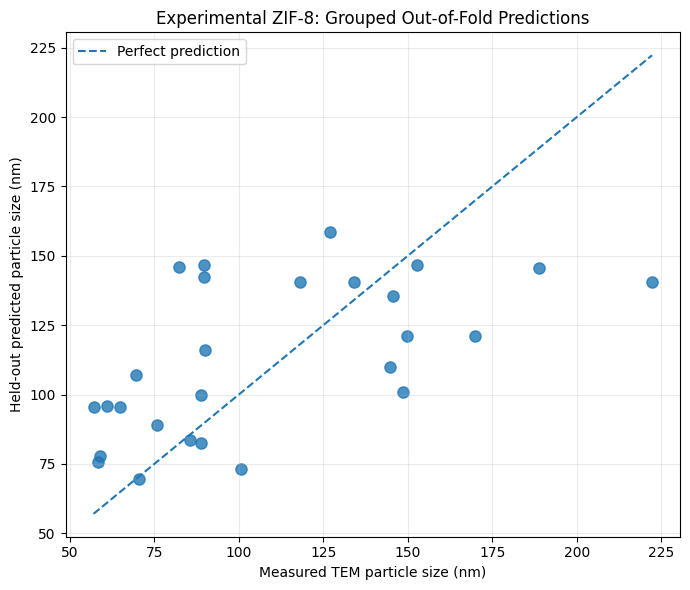

In [88]:
# Examine held-out Random Forest predictions and experimental prediction errors

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

cv = GroupKFold(n_splits=5)

out_of_fold_predictions = np.full(len(y_experimental), np.nan)
validation_fold = np.full(len(y_experimental), -1, dtype=int)

for fold_number, (train_idx, test_idx) in enumerate(
    cv.split(X_experimental, y_experimental, groups=experimental_groups),
    start=1
):
    model = clone(experimental_models["Random Forest"])

    model.fit(
        X_experimental.iloc[train_idx],
        y_experimental.iloc[train_idx]
    )

    out_of_fold_predictions[test_idx] = model.predict(
        X_experimental.iloc[test_idx]
    )

    validation_fold[test_idx] = fold_number

experimental_predictions = zif8_experimental[
    [
        "hmim_quantity_reported",
        "temperature_C",
        "polarity_reported",
        "particle_size_nm",
    ]
].copy()

experimental_predictions["predicted_size_nm"] = out_of_fold_predictions
experimental_predictions["absolute_error_nm"] = np.abs(
    experimental_predictions["particle_size_nm"]
    - experimental_predictions["predicted_size_nm"]
)
experimental_predictions["validation_fold"] = validation_fold

print("OUT-OF-FOLD PREDICTION SUMMARY")
print(
    "MAE:",
    round(
        mean_absolute_error(y_experimental, out_of_fold_predictions),
        2
    ),
    "nm"
)
print(
    "RMSE:",
    round(
        np.sqrt(mean_squared_error(y_experimental, out_of_fold_predictions)),
        2
    ),
    "nm"
)
print(
    "Overall out-of-fold R²:",
    round(r2_score(y_experimental, out_of_fold_predictions), 3)
)

print("\nFIVE LARGEST PREDICTION ERRORS")
display(
    experimental_predictions
    .sort_values("absolute_error_nm", ascending=False)
    .head(5)
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    experimental_predictions["particle_size_nm"],
    experimental_predictions["predicted_size_nm"],
    alpha=0.8,
    s=65
)

size_min = min(
    experimental_predictions["particle_size_nm"].min(),
    experimental_predictions["predicted_size_nm"].min()
)
size_max = max(
    experimental_predictions["particle_size_nm"].max(),
    experimental_predictions["predicted_size_nm"].max()
)

ax.plot(
    [size_min, size_max],
    [size_min, size_max],
    "--",
    label="Perfect prediction"
)

ax.set_xlabel("Measured TEM particle size (nm)")
ax.set_ylabel("Held-out predicted particle size (nm)")
ax.set_title("Experimental ZIF-8: Grouped Out-of-Fold Predictions")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [89]:
# Compare Ridge regression with the existing experimental models using identical grouped folds

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

experimental_models["Ridge regression"] = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

ridge_cv_results = cross_validate(
    experimental_models["Ridge regression"],
    X_experimental,
    y_experimental,
    groups=experimental_groups,
    cv=experimental_cv,
    scoring=experimental_scoring,
    n_jobs=1,
    error_score="raise",
)

ridge_summary = {
    "Model": "Ridge regression",
    "MAE_mean_nm": -ridge_cv_results["test_MAE"].mean(),
    "MAE_std_nm": ridge_cv_results["test_MAE"].std(),
    "RMSE_mean_nm": -ridge_cv_results["test_RMSE"].mean(),
    "R2_mean": ridge_cv_results["test_R2"].mean(),
    "R2_std": ridge_cv_results["test_R2"].std(),
}

experimental_comparison = pd.concat(
    [
        experimental_comparison[
            experimental_comparison["Model"] != "Ridge regression"
        ],
        pd.DataFrame([ridge_summary]),
    ],
    ignore_index=True,
)

print("EXPERIMENTAL MODEL COMPARISON")
print("Validation: GroupKFold, 5 splits, identical recorded conditions kept together")

display(
    experimental_comparison
    .sort_values("MAE_mean_nm")
    .round(3)
)


EXPERIMENTAL MODEL COMPARISON
Validation: GroupKFold, 5 splits, identical recorded conditions kept together


,Model,MAE_mean_nm,MAE_std_nm,RMSE_mean_nm,R2_mean,R2_std
1,Random Forest,29.922,8.777,34.753,-1.524,3.494
2,Ridge regression,31.886,10.122,35.445,-1.280,3.037
0,Baseline (training mean),40.204,11.564,44.893,-3.409,6.532


#### **Scientific observations — Experimental model evaluation**

The published experimental dataset contains **27 ZIF-8 particle-size records representing 23 distinct combinations of recorded synthesis inputs.** Models were evaluated using five-fold grouped cross-validation to prevent identical recorded conditions from appearing in both training and validation sets.

**Model comparison:** Random Forest achieved the lowest mean absolute error (**29.92 nm**), followed by Ridge regression (**31.89 nm**) and the training-mean baseline (**40.20 nm**). The Random Forest reduced mean absolute error by approximately **25.6% relative to the baseline**, suggesting that the experimental inputs contain some useful predictive information.

**Prediction behaviour:** The Random Forest's overall out-of-fold R² was **0.326**, but its mean fold-level R² was **−1.524**, with substantial variation between folds. The model tended to underestimate the largest measured particles and overestimate some smaller particles. All five largest absolute prediction errors occurred at the highest reported Hmim loading.

**Scientific interpretation:** These results support a preliminary relationship between synthesis conditions and measured particle size, but do not establish reliable generalisation. The small dataset, repeated recorded conditions with differing outcomes, and limited experimental coverage restrict predictive confidence. The model should not be treated as a validated optimisation tool or a mechanistic model of ZIF-8 crystallisation.

**Decision:** Retain the Random Forest as the experimental-data demonstration model because it achieved the lowest grouped cross-validation MAE among the models tested. Preserve the synthetic model separately for testing the agentic architecture.

### **10.3 Experimental Model Persistence and Provenance**

In [90]:
# Train and save the experimental Random Forest with provenance and validation metadata

import joblib

experimental_model = clone(experimental_models["Random Forest"])
experimental_model.fit(X_experimental, y_experimental)

experimental_model_path = "/content/zif8_experimental_random_forest.joblib"
experimental_metadata_path = "/content/zif8_experimental_model_metadata.json"

joblib.dump(experimental_model, experimental_model_path)

rf_results = experimental_comparison.loc[
    experimental_comparison["Model"] == "Random Forest"
].iloc[0]

experimental_model_metadata = {
    "model_name": "ZIF-8 experimental Random Forest",
    "model_type": "RandomForestRegressor",
    "scientific_status": "PRELIMINARY_EXPERIMENTAL_MODEL_NOT_EXTERNALLY_VALIDATED",
    "data_origin": "PUBLISHED_EXPERIMENTAL",
    "source_dataset_doi": "10.5281/zenodo.14063747",
    "source_article_doi": "10.1016/j.mtcomm.2024.111177",
    "measurement_method": "TEM/ImageJ",
    "target": "particle_size_nm",
    "features": experimental_features,
    "feature_units": {
        "hmim_quantity_reported": "unit not specified in spreadsheet",
        "temperature_C": "degrees Celsius",
        "polarity_reported": "reported polarity value",
    },
    "training_records": int(len(X_experimental)),
    "unique_recorded_conditions": int(experimental_groups.nunique()),
    "validation_method": "GroupKFold(n_splits=5)",
    "grouped_cv_mae_mean_nm": float(rf_results["MAE_mean_nm"]),
    "grouped_cv_rmse_mean_nm": float(rf_results["RMSE_mean_nm"]),
    "grouped_cv_r2_mean": float(rf_results["R2_mean"]),
    "overall_out_of_fold_r2": float(
        r2_score(y_experimental, out_of_fold_predictions)
    ),
    "observed_feature_ranges": {
        feature: {
            "min": float(X_experimental[feature].min()),
            "max": float(X_experimental[feature].max()),
        }
        for feature in experimental_features
    },
    "observed_particle_size_range_nm": {
        "min": float(y_experimental.min()),
        "max": float(y_experimental.max()),
    },
    "limitations": [
        "Only 27 experimental records and 23 distinct recorded conditions.",
        "Four recorded conditions occur more than once with differing particle sizes.",
        "Grouped cross-validation performance is variable.",
        "No independent external experimental validation.",
        "Predictions outside the observed input domain are not supported.",
        "Reported Hmim quantity units require verification.",
        "Model does not establish a crystallisation mechanism.",
    ],
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
}

with open(experimental_metadata_path, "w", encoding="utf-8") as file:
    json.dump(experimental_model_metadata, file, indent=2)

print("EXPERIMENTAL MODEL SAVED")
print("Model:", experimental_model_path)
print("Metadata:", experimental_metadata_path)
print("Scientific status:", experimental_model_metadata["scientific_status"])
print("Training records:", experimental_model_metadata["training_records"])
print("Validation MAE:", round(experimental_model_metadata["grouped_cv_mae_mean_nm"], 2), "nm")

print("\nEXPERIMENTAL MODEL INPUT DOMAIN")
display(pd.DataFrame(experimental_model_metadata["observed_feature_ranges"]).T)


EXPERIMENTAL MODEL SAVED
Model: /content/zif8_experimental_random_forest.joblib
Metadata: /content/zif8_experimental_model_metadata.json
Scientific status: PRELIMINARY_EXPERIMENTAL_MODEL_NOT_EXTERNALLY_VALIDATED
Training records: 27
Validation MAE: 29.92 nm

EXPERIMENTAL MODEL INPUT DOMAIN


,min,max
hmim_quantity_reported,1.9636,4.5818
temperature_C,0.0000,50.0000
polarity_reported,37.1900,55.5500


### **10.4 MCP Integration and Scientific Safeguards**

In [95]:
# Save recorded experimental conditions and register the complete prediction tool in the MCP server

recorded_conditions_path = "/content/zif8_experimental_conditions.csv"

X_experimental.drop_duplicates().to_csv(
    recorded_conditions_path,
    index=False,
)

mcp_server_path = Path("/content/zif8_mcp_server.py")

if not mcp_server_path.exists():
    raise FileNotFoundError(
        f"MCP server not found: {mcp_server_path}"
    )

server_code = mcp_server_path.read_text(encoding="utf-8")

experimental_tool_code = '''
@mcp.tool()
def predict_experimental_zif8_size(
    hmim_quantity_reported: float,
    temperature_C: float,
    polarity_reported: float,
) -> dict:
    """Estimate ZIF-8 TEM particle size using a preliminary experimental model.

    Hmim quantity uses the original dataset's numerical scale.
    Its physical unit is not established from the spreadsheet.
    Predictions have not been independently validated.
    """
    import json
    import joblib
    import pandas as pd

    with open(
        "/content/zif8_experimental_model_metadata.json",
        "r",
        encoding="utf-8",
    ) as file:
        metadata = json.load(file)

    inputs = {
        "hmim_quantity_reported": hmim_quantity_reported,
        "temperature_C": temperature_C,
        "polarity_reported": polarity_reported,
    }

    for feature, value in inputs.items():
        bounds = metadata["observed_feature_ranges"][feature]

        if not bounds["min"] <= value <= bounds["max"]:
            return {
                "status": "OUTSIDE_EXPERIMENTAL_DOMAIN",
                "predicted_particle_size_nm": None,
                "message": (
                    f"{feature}={value} is outside the observed range "
                    f"[{bounds['min']}, {bounds['max']}]."
                ),
                "scientific_status": metadata["scientific_status"],
            }

    recorded_conditions = pd.read_csv(
        "/content/zif8_experimental_conditions.csv"
    )

    recorded_mask = pd.Series(
        True,
        index=recorded_conditions.index,
    )

    for feature, value in inputs.items():
        recorded_mask &= (
            recorded_conditions[feature] - value
        ).abs() < 1e-6

    condition_recorded = bool(recorded_mask.any())

    model = joblib.load(
        "/content/zif8_experimental_random_forest.joblib"
    )

    input_frame = pd.DataFrame(
        [inputs],
        columns=metadata["features"],
    )

    predicted_size_nm = float(model.predict(input_frame)[0])

    return {
        "status": (
            "RECORDED_CONDITION_MODEL_ESTIMATE"
            if condition_recorded
            else "UNTESTED_CONDITION_MODEL_ESTIMATE"
        ),
        "predicted_particle_size_nm": round(predicted_size_nm, 2),
        "prediction_unit": "nm",
        "input_conditions": inputs,
        "condition_present_in_dataset": condition_recorded,
        "measurement_basis": metadata["measurement_method"],
        "data_source_doi": metadata["source_dataset_doi"],
        "scientific_status": metadata["scientific_status"],
        "grouped_cv_mae_mean_nm": round(
            metadata["grouped_cv_mae_mean_nm"], 2
        ),
        "warning": (
            "This is a fitted-model estimate, not a new experimental "
            "measurement. The model uses 27 published records and "
            "has not been independently validated. Grouped "
            "cross-validation MAE is approximately 29.92 nm; "
            "this is not an individual prediction uncertainty interval. "
            + (
                "The exact input combination appears in the dataset."
                if condition_recorded
                else "The exact input combination was not recorded "
                     "in the experimental dataset."
            )
        ),
    }
'''

tool_marker = "@mcp.tool()\ndef predict_experimental_zif8_size("
startup_marker = '\nif __name__ == "__main__":'

if startup_marker not in server_code:
    raise ValueError("MCP server startup block not found.")

startup_position = server_code.index(startup_marker)

if tool_marker in server_code:
    tool_position = server_code.index(tool_marker)

    if tool_position > startup_position:
        raise ValueError(
            "Existing experimental tool is after the server startup block."
        )

    updated_server_code = (
        server_code[:tool_position]
        + experimental_tool_code
        + server_code[startup_position:]
    )
    action = "Updated existing experimental MCP tool"
else:
    updated_server_code = (
        server_code[:startup_position]
        + "\n"
        + experimental_tool_code
        + server_code[startup_position:]
    )
    action = "Registered new experimental MCP tool"

ast.parse(updated_server_code)

mcp_server_path.write_text(
    updated_server_code,
    encoding="utf-8",
)

print(action)
print("Recorded experimental conditions:", recorded_conditions_path)
print("Unique recorded conditions:", len(X_experimental.drop_duplicates()))
print("Python syntax verified.")

Updated existing experimental MCP tool
Recorded experimental conditions: /content/zif8_experimental_conditions.csv
Unique recorded conditions: 23
Python syntax verified.


In [96]:
# Verify that the MCP bridge discovers all five tools, including the experimental predictor

mcp_tool_discovery = run_mcp_bridge({"action": "list"})

if isinstance(mcp_tool_discovery, dict):
    discovered_tools = mcp_tool_discovery.get("tools", [])
elif isinstance(mcp_tool_discovery, list):
    discovered_tools = mcp_tool_discovery
else:
    raise TypeError(
        f"Unexpected MCP bridge response: {type(mcp_tool_discovery).__name__}"
    )

discovered_names = [
    tool["name"]
    for tool in discovered_tools
]

expected_tools = {
    "search_openalex_papers",
    "search_crossref_papers",
    "list_verified_experiments",
    "predict_zif8_particle_size",
    "predict_experimental_zif8_size",
}

print("MCP TOOLS DISCOVERED:", len(discovered_names))

for name in discovered_names:
    print(" -", name)

missing_tools = expected_tools - set(discovered_names)

if missing_tools:
    raise RuntimeError(
        f"Expected MCP tools not discovered: {sorted(missing_tools)}"
    )

print("\nSUCCESS: All five expected tools are discoverable through MCP.")

experimental_tool_schema = next(
    tool for tool in discovered_tools
    if tool["name"] == "predict_experimental_zif8_size"
)

print("\nEXPERIMENTAL TOOL INPUT SCHEMA")
print(
    json.dumps(
        experimental_tool_schema["input_schema"],
        indent=2
    )
)


MCP TOOLS DISCOVERED: 5
 - search_openalex_papers
 - search_crossref_papers
 - list_verified_experiments
 - predict_zif8_particle_size
 - predict_experimental_zif8_size

SUCCESS: All five expected tools are discoverable through MCP.

EXPERIMENTAL TOOL INPUT SCHEMA
{
  "properties": {
    "hmim_quantity_reported": {
      "title": "Hmim Quantity Reported",
      "type": "number"
    },
    "temperature_C": {
      "title": "Temperature C",
      "type": "number"
    },
    "polarity_reported": {
      "title": "Polarity Reported",
      "type": "number"
    }
  },
  "required": [
    "hmim_quantity_reported",
    "temperature_C",
    "polarity_reported"
  ],
  "title": "predict_experimental_zif8_sizeArguments",
  "type": "object"
}


In [97]:
# Test experimental MCP predictions at recorded, out-of-range, and untested conditions

experimental_mcp_tests = {
    "Recorded experimental condition": {
        "hmim_quantity_reported": 1.9636,
        "temperature_C": 24,
        "polarity_reported": 55.55,
    },
    "Outside experimental range": {
        "hmim_quantity_reported": 6.0,
        "temperature_C": 24,
        "polarity_reported": 55.55,
    },
    "Intermediate untested Hmim level": {
        "hmim_quantity_reported": 2.5,
        "temperature_C": 24,
        "polarity_reported": 55.55,
    },
}

experimental_mcp_responses = {}

for test_name, arguments in experimental_mcp_tests.items():
    response = run_mcp_bridge({
        "action": "call",
        "name": "predict_experimental_zif8_size",
        "arguments": arguments,
    })

    experimental_mcp_responses[test_name] = response

    print(f"\n{'=' * 65}")
    print(test_name.upper())
    print(json.dumps(response, indent=2, default=str))



RECORDED EXPERIMENTAL CONDITION
{
  "is_error": false,
  "content": [
    "{\n  \"status\": \"RECORDED_CONDITION_MODEL_ESTIMATE\",\n  \"predicted_particle_size_nm\": 69.51,\n  \"prediction_unit\": \"nm\",\n  \"input_conditions\": {\n    \"hmim_quantity_reported\": 1.9636,\n    \"temperature_C\": 24.0,\n    \"polarity_reported\": 55.55\n  },\n  \"condition_present_in_dataset\": true,\n  \"measurement_basis\": \"TEM/ImageJ\",\n  \"data_source_doi\": \"10.5281/zenodo.14063747\",\n  \"scientific_status\": \"PRELIMINARY_EXPERIMENTAL_MODEL_NOT_EXTERNALLY_VALIDATED\",\n  \"grouped_cv_mae_mean_nm\": 29.92,\n  \"warning\": \"This is a fitted-model estimate, not a new experimental measurement. The model uses 27 published records and has not been independently validated. Grouped cross-validation MAE is approximately 29.92 nm; this is not an individual prediction uncertainty interval. The exact input combination appears in the dataset.\"\n}"
  ]
}

OUTSIDE EXPERIMENTAL RANGE
{
  "is_error": false

### **10.5 Autonomous Claude–MCP Model Invocation**

In [98]:
# Test Claude's autonomous selection of the experimental ZIF-8 prediction tool

mcp_tools = run_mcp_bridge({"action": "list"})

mcp_claude_tools = [
    {
        "name": tool["name"],
        "description": tool.get("description") or "",
        "input_schema": tool["input_schema"],
    }
    for tool in mcp_tools
]

registered_names = [tool["name"] for tool in mcp_claude_tools]

assert "predict_experimental_zif8_size" in registered_names, (
    "Experimental prediction tool is missing from Claude's MCP registry."
)

print("MCP TOOLS AVAILABLE TO CLAUDE")
for name in registered_names:
    print(" -", name)

experimental_agent_question = (
    "Use the published experimental ZIF-8 model, not the synthetic "
    "demonstration model, to estimate TEM particle size for "
    "Hmim quantity 1.9636 on the dataset's reported numerical scale, "
    "temperature 24 degrees Celsius, and polarity 55.55. "
    "Call the appropriate MCP tool. Report the predicted size, "
    "whether the condition was recorded in the experimental dataset, "
    "the dataset DOI, and the model's validation limitations. "
    "Do not present the model prediction as an experimental measurement."
)

experimental_agent_result = run_mcp_research_agent(
    experimental_agent_question,
    max_rounds=5,
)

print("\nEXPERIMENTAL MCP TOOL AUDIT")
for entry in experimental_agent_result["tool_log"]:
    print(
        "Tool:", entry["tool"],
        "| Error:", entry["is_error"],
    )

experimental_tool_called = any(
    entry["tool"] == "predict_experimental_zif8_size"
    and not entry["is_error"]
    for entry in experimental_agent_result["tool_log"]
)

print(
    "\nExperimental MCP prediction tool successfully called:",
    experimental_tool_called,
)


MCP TOOLS AVAILABLE TO CLAUDE
 - search_openalex_papers
 - search_crossref_papers
 - list_verified_experiments
 - predict_zif8_particle_size
 - predict_experimental_zif8_size
Round 1: Claude selected predict_experimental_zif8_size
Round 1: Claude selected list_verified_experiments

CLAUDE'S FINAL ANSWER:

## Results

**Predicted TEM Particle Size:** 69.51 nm

**Condition Recorded in Dataset:** Yes — the exact input combination (Hmim quantity 1.9636, temperature 24°C, polarity 55.55) is present in the experimental dataset.

**Dataset DOI:** 10.5281/zenodo.14063747

**Model Validation Limitations:**

1. **No External Validation:** This is a preliminary experimental model that has not been independently validated by other research groups or laboratories.

2. **Limited Dataset Size:** The model was trained on only 27 published records, which is a relatively small dataset for robust generalization.

3. **Grouped Cross-Validation Performance:** The grouped cross-validation mean absolute erro

#### **Observations — Autonomous Experimental Model Invocation**

Claude selected 'predict_zif8_particle_size' from the five scientific tools exposed by the MCP server. The execution audit confirmed that the tool call completed successfully.

For a recorded synthesis condition—Hmim quantity 1.9636 on the dataset's reported numerical scale, temperature 24 °C and polarity 55.55—the experimental Random Forest returned a **predicted TEM particle size of 69.51 nm.**

Claude identified the result as a model-derived estimate rather than a new experimental measurement, confirmed that the input combination was recorded in the published dataset, and reported the source DOI and validation information. The model was trained on 27 experimental records and achieved a grouped cross-validation MAE of **29.92 nm**; no independent experimental validation was performed.

**Technical outcome:** The execution demonstrates coordination between Claude, a real MCP server and a regression model trained on published experimental measurements. The agent communicated the prediction together with its provenance and scientific status.

## **11. Conclusions and Future Directions**

### **11.1 Summary of Research Outcomes**

This project developed and demonstrated an agentic scientific research workflow for solution-grown ZIF-8 nanocrystals, combining literature retrieval, structured experimental evidence, machine-learning regression and autonomous tool execution.

The principal outcomes are:

**Scientific literature and provenance:** OpenAlex and Crossref were integrated for publication discovery, while SQLite was used to organise bibliographic metadata, curated references and source-traceable experimental records. A verified synthesis experiment from the scientific literature was recorded with its reported conditions and particle-size measurement method.

**Agentic AI and MCP integration:** A Claude research agent was implemented first using native tool calling and subsequently connected to an independent Model Context Protocol (MCP) server. The MCP implementation enabled scientific tool discovery, execution and auditable agent-directed selection across literature, experimental-data and prediction tools.

**Machine-learning workflow:** A synthetic regression demonstration established the model-training, persistence and MCP-integration pipeline. A separate regression analysis used 27 published ZIF-8 experimental records, preserving the distinction between simulated data and experimentally measured particle sizes.

**Experimental model evaluation:** Grouped five-fold cross-validation was used to evaluate a Random Forest regressor, Ridge regression and a mean-prediction baseline. The Random Forest achieved the lowest mean absolute error, approximately **29.92 nm**, compared with **31.89 nm** for Ridge and **40.20 nm** for the baseline.

**Autonomous experimental prediction:** Claude successfully selected and invoked the experimental Random Forest through MCP. For a synthesis condition recorded in the published dataset, the model returned an estimated TEM particle size of **69.51 nm**, accompanied by source provenance, validation information and an explicit model-estimate status.

Together, these results demonstrate an end-to-end connection between scientific information retrieval, structured evidence, predictive modelling and agentic execution.

### **11.2 Scientific Interpretation and Limitations**

The experimental regression results provide an initial assessment of the relationship between reported synthesis parameters and ZIF-8 particle size. The Random Forest performed better than the linear Ridge model and the baseline under the selected grouped validation procedure, suggesting that nonlinear relationships may be relevant within this dataset. However, the modest difference between Random Forest and Ridge regression, together with the limited number of experimental records and variation between validation folds, does not establish that Random Forest will perform better on independent experimental datasets.

The experimental dataset contains **27 records representing 23 distinct combinations of the recorded inputs.** Four input combinations occur more than once, with differences in measured particle size. Grouped cross-validation keeps records with identical input conditions together, reducing information leakage between training and validation folds. Nevertheless, the resulting error estimates reflect performance within this particular published dataset, not independently established accuracy across different laboratories or synthesis protocols.

The regression model uses three recorded inputs: Hmim quantity, temperature and solvent polarity. Other potentially influential synthesis variables are not independently represented in the fitted model. The Hmim quantity is retained on the dataset's reported numerical scale because its physical unit was not independently established from the retrieved spreadsheet.

The approximately 30 nm SEM particle-size record curated from Cookney's thesis is maintained separately from the Du et al. TEM/ImageJ dataset. These measurements originate from different experimental sources and characterisation contexts and are not treated as directly interchangeable regression targets.

The MCP prediction tool distinguishes recorded input combinations, untested combinations within the observed numerical ranges and requests outside those ranges. These safeguards improve the transparency of model use but do not constitute experimental validation. Predictions are therefore interpreted as preliminary model estimates rather than verified synthesis outcomes or optimisation recommendations.

### **11.3 Future Directions**

The most useful next development steps are:

**Expand and harmonise experimental evidence.** Incorporate additional verified, solution-grown ZIF-8 synthesis datasets with explicit precursor concentrations, solvent compositions, reaction conditions and particle-size characterisation methods. Preserve study-level provenance and measurement differences.

**Strengthen predictive validation.** Evaluate the regression workflow on independently sourced experiments and, where sufficient data become available, use study-level or laboratory-level validation to assess transferability beyond the original dataset.

**Improve chemical feature representation.** Clarify the units and definitions of reported synthesis parameters, investigate physically meaningful variables such as ligand-to-metal ratio and solvent composition, and assess correlated descriptors before expanding the feature set.

**Develop model interpretation and uncertainty reporting.** Investigate feature effects, prediction sensitivity and uncertainty estimates, while distinguishing statistical associations from established chemical mechanisms.

**Extend the agentic research workflow.** Connect additional scientific data resources and validated computational tools through MCP, with explicit provenance, structured outputs and auditable execution. A future system could assist in proposing candidate experiments for human review and subsequent laboratory validation.

### **11.4 Final Perspective**

The central contribution of this prototype is the integration of scientific evidence and computational tools within an agentic workflow. Claude does not independently establish chemical truth; it coordinates retrieval, structured data access and model execution, while the underlying sources and computational methods provide the evidence to be evaluated.

The project demonstrates a practical foundation for provenance-aware scientific AI in materials research. Its further development depends on stronger experimental datasets, independent validation and continued separation of measured observations from model-generated estimates.